# 05 — SCAR-MLKEM: proposed controller, development evidence and frozen design

**Stage.** Development of the single proposed method, **SCAR-MLKEM** (Security-Constrained Adaptive Reconstruction and caching for ML-KEM-768), on Raspberry Pi 5, before any independent evaluation.

**Goal.** Establish, on development workloads only, whether a bounded causal controller that retains public key material and expanded secret material under explicit memory and lifetime limits lowers the *complete request-phase CPU cost* of ML-KEM-768 decapsulation on a constrained device, and freeze one architecture for the independent confirmation in Notebook 06.

**Research questions.** RQ4a: how much of the standard seed-only reconstruction cost can retention remove, and which part of it requires the adaptive controller rather than a fixed cache policy? RQ4b: do the five SCAR components each contribute on development data? RQ4c: how sensitive is the result to the secret lifetime limit, and what is the logical ceiling of secret retention under the mandatory-clear barrier?

**Data.** Frozen eight-state operation costs from the shared Pi calibration, the immutable 40-process development screen already acquired for the shared compact-secret controller, and one new prospectively planned development series on Raspberry Pi 5 over all ten workload families, two arena budgets and three development seeds per family. No reserved test seed is generated or read here.

**Previous stages.** Notebook 01 fixed the observation unit (one decapsulation request; one native session as the replication unit) and the development/test boundary. Notebook 02 produced causal features and leakage-safe splits. Notebooks 03 and 04 measured baselines and modern cache policies on the earlier harness and motivated a cost-aware admission controller with explicit retention limits.

**Boundaries.** All analysis runs on the MacBook; all cryptographic timing runs on the Pi through SSH commands visible in the cells. ML-KEM-768 parameters, key sizes and security level are unchanged. Energy is not measured (no external meter). Development results select and freeze the design; they are not independent evidence of superiority.

In [1]:
from pathlib import Path
import hashlib, io, json, os, re, shlex, subprocess, sys, tarfile, textwrap, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Image, Markdown, clear_output

NB = "05"
# Resolve the repository root from either the root directory or notebooks/.
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks").is_dir() and (p / "dataset").is_dir()), None)
assert ROOT is not None, "run this notebook from inside the repository"
def relocate(rel):
    """Map a path recorded at acquisition time (original project layout) onto this repository's layout."""
    rel = str(rel)
    for old, new in (("Dataset/Raw/PiExperiments/", "dataset/raw/"), ("Dataset/Raw/", "dataset/raw/"), ("Raw/", "raw/"),
                     ("Dataset/Interim/", "dataset/interim/"), ("Dataset/Processed/", "dataset/processed/"),
                     ("Dataset/Splits/", "dataset/splits/"), ("Dataset/Provenance/", "dataset/provenance/"),
                     ("Artifacts/Models/", "support/models/"), ("Artifacts/Binaries/", "support/binaries/"),
                     ("Configs/", "support/configs/"), ("Manifests/", "support/manifests/"), ("Native/", "support/native/"),
                     ("Reports/CoreCalibration/", "support/calibration/"), ("Tables/", "artifacts/"), ("Figures/", "figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
def acquisition_path(path):
    """Inverse of relocate: a repository path written in the acquisition-time layout used inside frozen records."""
    path = Path(path)
    rel = str(path.resolve().relative_to(ROOT)) if path.is_absolute() else str(path)
    for old, new in (("dataset/raw/MLKEM_TestVectors/", "Dataset/Raw/MLKEM_TestVectors/"), ("dataset/raw/IoT23/", "Dataset/Raw/IoT23/"),
                     ("dataset/raw/", "Dataset/Raw/PiExperiments/"), ("dataset/interim/", "Dataset/Interim/"),
                     ("dataset/processed/", "Dataset/Processed/"), ("dataset/splits/", "Dataset/Splits/"),
                     ("dataset/provenance/", "Dataset/Provenance/"), ("support/models/", "Artifacts/Models/"),
                     ("support/binaries/", "Artifacts/Binaries/"), ("support/configs/", "Configs/"), ("support/manifests/", "Manifests/"),
                     ("support/native/", "Native/"), ("support/calibration/", "Reports/CoreCalibration/"),
                     ("artifacts/", "Tables/"), ("figures/", "Figures/")):
        if rel.startswith(old):
            return new + rel[len(old):]
    return rel
DATA, TABLES, FIGURES = ROOT / "dataset", ROOT / "artifacts", ROOT / "figures"
RAW, INTERIM = DATA / "raw", DATA / "interim"
MANIFESTS, CONFIGS, CALIBRATION = ROOT / "support/manifests", ROOT / "support/configs", ROOT / "support/calibration"
for p in (TABLES, FIGURES, INTERIM, MANIFESTS / "NotebookRuns"):
    p.mkdir(parents=True, exist_ok=True)
RNG_SEED = 20261020
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
try:
    font_manager.findfont("Times New Roman", fallback_to_default=False); FONT_FAMILY = "Times New Roman"
except ValueError:
    FONT_FAMILY = "serif"  # the published figures use Times New Roman; any serif font keeps the layout
mpl.rcParams.update({"font.family": FONT_FAMILY, "font.size": 18,
    "axes.titlesize": 20, "axes.labelsize": 20, "xtick.labelsize": 18,
    "ytick.labelsize": 18, "legend.fontsize": 18, "figure.dpi": 350,
    "savefig.dpi": 350, "axes.unicode_minus": True, "pdf.fonttype": 42,
    "legend.frameon": False})
COLORS = {"none": "#4D4D4D", "public_s3": "#0072B2", "sieve": "#009E73",
          "lecar": "#CC79A7", "tiny": "#E69F00", "scar": "#D55E00"}
LABELS = {"none": "Seed-only (standard)", "public_s3": "Public S3-FIFO",
          "sieve": "SIEVE", "lecar": "LeCaR", "tiny": "TinyLFU", "scar": "SCAR-MLKEM"}
POLICIES = ["none", "public_s3", "sieve", "lecar", "tiny", "scar"]
FAMILIES = ["uniform", "poisson", "zipf", "bursty", "periodic", "nonstationary",
            "abrupt", "thrashing", "hotcold", "varying_contexts"]
ARENAS = [32768, 65536]
COST_NAMES = ["C00", "C01", "C10", "C11", "addP", "addS", "eraseP", "eraseS"]

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()
def sha_bytes(data):
    return hashlib.sha256(data).hexdigest()
def read_json(path):
    return json.loads(Path(path).read_text())
def canonical(obj):
    return (json.dumps(obj, sort_keys=True, indent=2, allow_nan=False) + "\n").encode()
def write_json(path, obj):
    """Write once; an existing identical file is accepted, a different one is refused."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    data = canonical(obj)
    if path.exists():
        assert path.read_bytes() == data, f"refusing to overwrite a different {path.name}"
        return path
    path.write_bytes(data); return path
def save_table(frame, name, *, show=True, index=False):
    frame.to_csv(TABLES / f"{NB}_{name}.csv", index=index)
    if show:
        display(frame if index else frame.reset_index(drop=True))
def save_figure(fig, name, source=None):
    """Save PNG and PDF at 350 DPI, then show the saved PNG exactly once."""
    fig.set_layout_engine("constrained")
    png, pdf = FIGURES / f"{NB}_{name}.png", FIGURES / f"{NB}_{name}.pdf"
    fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=0.15); fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=0.15)
    plt.close(fig)
    if source is not None:
        source.to_csv(TABLES / f"{NB}_{name}_source.csv", index=False)
    display(Image(filename=str(png), width=900))
def check_font_sizes(fig):
    sizes = {round(t.get_fontsize(), 1) for t in fig.findobj(mpl.text.Text) if t.get_text().strip()}
    assert sizes and min(sizes) >= 18 and max(sizes) <= 20, sizes
# Raspberry Pi 5 transport: the Pi executes native cryptographic processes; this kernel stays on the MacBook.
PI_SETUP = Path(os.environ.get("PI_SETUP_DIR", "~/.scar_mlkem_pi")).expanduser()
PI_ENABLED = (PI_SETUP / "ssh_config").is_file()  # without a board every saved campaign is verified offline
PI_ALIAS, PI_REMOTE_ROOT = "nazira-pi", "/home/research/Nazira_Crystals-Cyber"
PI_BASE = ["ssh", "-F", str(PI_SETUP / "ssh_config"), "-o", "BatchMode=yes", "-o", "ConnectTimeout=8"]

def pi_candidates():
    """Primary mDNS alias first, then IPv6 link-local fallbacks on active interfaces."""
    yield []
    try:
        host = subprocess.run(["dscacheutil", "-q", "host", "-a", "name", "raspberrypi.local"],
                              capture_output=True, text=True, timeout=5).stdout
    except (OSError, subprocess.SubprocessError):
        host = ""
    v6 = re.findall(r"ipv6_address:\s*(\S+)", host)
    ifaces = re.findall(r"^(en\d+):", subprocess.run(["ifconfig"], capture_output=True, text=True).stdout, re.M)
    for addr in v6:
        for ifc in ifaces:
            yield ["-o", f"HostName={addr}%%{ifc}"]

def pi_run(command, *, input_bytes=None, timeout=120, attempts=30):
    """Run one remote shell command; returns CompletedProcess or raises after all transports fail.
    The USB-LAN link to the Pi drops for short periods, so each command tolerates about five minutes of outage."""
    if not PI_ENABLED:
        raise ConnectionError("Raspberry Pi transport is not configured (set PI_SETUP_DIR)")
    last = None
    for attempt in range(attempts):
        for extra in pi_candidates():
            try:
                result = subprocess.run(PI_BASE + extra + [PI_ALIAS, command], input=input_bytes,
                                        capture_output=True, timeout=timeout)
            except subprocess.TimeoutExpired as exc:
                last = exc; continue
            if result.returncode == 255:
                last = result; continue
            return result
        time.sleep(10)
    raise ConnectionError(f"Raspberry Pi unreachable after {attempts} attempts: {last}")

def pi_text(command, **kw):
    r = pi_run(command, **kw); assert r.returncode == 0, r.stderr.decode()[:400]
    return r.stdout.decode()

def pi_sudo(command, **kw):
    """Only CPU-governor changes need sudo; the password is read from the project's private credential file and never shown."""
    secret = read_json(PI_SETUP / "private/credentials.json")["password"] + "\n"
    r = pi_run("sudo -S -p '' " + command, input_bytes=secret.encode(), **kw)
    assert r.returncode == 0, "sudo command failed"
    return r.stdout.decode()

def pi_governor(value=None):
    if value is not None:
        pi_sudo("sh -c " + shlex.quote("for c in /sys/devices/system/cpu/cpufreq/policy*/scaling_governor; do echo " + value + " > $c; done"))
    return pi_text("cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_governor").strip()

def pi_upload(paths):
    """Upload project-relative files to the same relative paths on the Pi."""
    payload = io.BytesIO()
    with tarfile.open(fileobj=payload, mode="w:gz") as tar:
        for p in paths:
            tar.add(p, arcname=acquisition_path(Path(p).resolve()))
    pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && tar -xzf -", input_bytes=payload.getvalue())

def pi_fetch(relative_dir):
    """Fetch a remote directory into the identical local path; existing files must be byte-identical."""
    for attempt in range(4):
        data = pi_run(f"cd {shlex.quote(PI_REMOTE_ROOT)} && tar -czf - {shlex.quote(relative_dir)}", timeout=900)
        if data.returncode == 0:
            break
        time.sleep(5)
    assert data.returncode == 0, data.stderr.decode()[:300]
    with tarfile.open(fileobj=io.BytesIO(data.stdout), mode="r:gz") as tar:
        for member in tar:
            target = (ROOT / relocate(member.name)).resolve()
            assert target.is_relative_to(ROOT / relocate(relative_dir))
            if member.isdir():
                target.mkdir(parents=True, exist_ok=True); continue
            assert member.isfile()
            content = tar.extractfile(member).read()
            if target.exists():
                assert target.read_bytes() == content, member.name
            else:
                target.parent.mkdir(parents=True, exist_ok=True); target.write_bytes(content)
WORKER_SOURCE = r'''#!/usr/bin/env python3
"""Sequential native campaign worker for Raspberry Pi 5.
Runs every planned process exactly once in registered order. No retry, no selection,
no analysis. Every outcome, including failures, is recorded."""
import hashlib, json, os, platform, re, signal, subprocess, sys, time
from pathlib import Path

def sha(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def write(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".partial")
    tmp.write_text(json.dumps(obj, sort_keys=True, indent=2, allow_nan=False) + "\n")
    os.replace(tmp, path)

def read_sys(p):
    try:
        return Path(p).read_text().strip()
    except OSError as exc:
        return "unavailable:" + type(exc).__name__

def environment(cpu):
    try:
        throttled = subprocess.run(["vcgencmd", "get_throttled"], capture_output=True, text=True, timeout=5).stdout.strip()
    except (OSError, subprocess.SubprocessError) as exc:
        throttled = "unavailable:" + type(exc).__name__
    return dict(governor=read_sys(f"/sys/devices/system/cpu/cpu{cpu}/cpufreq/scaling_governor"),
                frequency_khz=read_sys(f"/sys/devices/system/cpu/cpu{cpu}/cpufreq/scaling_cur_freq"),
                temperature_millic=read_sys("/sys/class/thermal/thermal_zone0/temp"),
                throttled=throttled, loadavg=read_sys("/proc/loadavg"), kernel=platform.release(),
                machine=platform.machine(), utc=time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()))

def kv(text):
    values = {}
    for key, val in re.findall(r"([A-Za-z_]\w*)=([^\s]+)", text):
        if key in values and values[key] != val:
            values[key + "__conflict"] = val
        values.setdefault(key, val)
    return values

def main():
    assert len(sys.argv) == 3, "usage: worker.py SPEC_JSON SPEC_SHA256"
    spec_path, expected = Path(sys.argv[1]), sys.argv[2]
    assert sha(spec_path) == expected, "spec digest mismatch"
    spec = json.loads(spec_path.read_text())
    root = Path(spec["remote_root"]); os.chdir(root)
    assert sha(spec["binary"]) == spec["binary_sha256"] and sha(spec["library"]) == spec["library_sha256"]
    raw = root / spec["raw_dir"]; raw.mkdir(parents=True, exist_ok=False)
    write(raw / "spec.json", spec)
    cpu, names = spec["cpu"], spec["cost_names"]
    cost_args = [format(spec["costs_ns"][k], ".17g") for k in names]
    records, passed, failed, aborted = [], 0, 0, None
    first_env = environment(cpu)
    for index, row in enumerate(spec["plan"]):
        before = environment(cpu)
        if before["governor"] != spec["governor"] or not before["throttled"].endswith("=0x0"):
            aborted = dict(index=index, reason="environment", environment=before); break
        args = ["run", row["session_id"], row["family"], str(row["seed"]), str(spec["requests"]),
                str(spec["contexts"]), str(spec["interval_us"]), spec["split"], row["policy"],
                str(row["arena_bytes"]), str(row["ttl_ms"]), str(spec["guard_us"]), str(spec["horizon_ms"]),
                str(spec["history_capacity"]), str(row["components"])] + cost_args + [str(spec["drift"])]
        argv = ["taskset", "-c", str(cpu), spec["binary"]] + args
        env = {k: v for k, v in os.environ.items() if not k.startswith("SCAR_")}
        if row["policy"] == "scar":
            env.update(SCAR_K=str(spec["scar"]["k"]), SCAR_NU=str(spec["scar"]["nu"]), SCAR_MARGIN=str(spec["scar"]["margin"]))
        base = raw / row["session_id"]
        started = time.monotonic()
        with open(str(base) + ".stdout.csv", "wb") as out, open(str(base) + ".stderr.txt", "wb") as err:
            proc = subprocess.Popen(argv, stdout=out, stderr=err, env=env, stdin=subprocess.DEVNULL, start_new_session=True)
            try:
                rc = proc.wait(timeout=spec["timeout_seconds"])
            except subprocess.TimeoutExpired:
                os.killpg(proc.pid, signal.SIGKILL); rc = proc.wait()
        wall = time.monotonic() - started
        after = environment(cpu)
        meta = kv(Path(str(base) + ".stderr.txt").read_text(errors="replace"))
        rows = sum(1 for _ in open(str(base) + ".stdout.csv", "rb")) - 1
        ok = rc == 0 and meta.get("native_success") == "1" and meta.get("request_count") == str(spec["requests"]) and rows == spec["requests"]
        status = "passed" if ok else "failed"
        passed += ok; failed += (not ok)
        record = dict(index=index, row=row, argv=argv, before=before, after=after, returncode=rc,
                      wall_seconds=wall, status=status, metadata=meta, stdout_rows=rows,
                      stdout_sha256=sha(str(base) + ".stdout.csv"), stderr_sha256=sha(str(base) + ".stderr.txt"))
        write(str(base) + ".record.json", record); records.append(record)
        write(raw / "progress.json", dict(attempted=index + 1, passed=passed, failed=failed, planned=len(spec["plan"])))
        time.sleep(spec["cooldown_seconds"])
    files = {str(p.relative_to(raw)): sha(p) for p in sorted(raw.rglob("*")) if p.is_file() and p.name != "progress.json"}
    write(raw / "done.json", dict(status="aborted" if aborted else "completed", aborted=aborted,
          attempted=len(records), passed=passed, failed=failed, planned=len(spec["plan"]),
          spec_sha256=expected, environment_first=first_env, environment_last=environment(cpu),
          python=platform.python_version(), files=files))

if __name__ == "__main__":
    main()
'''
def campaign_plan_rows(families, seeds_by_family, arenas, settings, split):
    """Enumerate processes: one native session per (family, seed, arena, setting), in registered order."""
    rows = []
    for family in families:
        for seed in seeds_by_family[family]:
            for arena in arenas:
                for s in settings:
                    rows.append(dict(session_id=f"{split}_{family}_{seed}_{arena // 1024}k_{s['name']}",
                                     family=family, seed=int(seed), arena_bytes=int(arena), setting=s["name"],
                                     policy=s["policy"], components=int(s["components"]), ttl_ms=int(s["ttl_ms"])))
    assert len({r["session_id"] for r in rows}) == len(rows)
    return rows

def registered_seeds(exclude=None):
    """Every seed that any manifest or configuration in the project has ever registered,
    optionally ignoring one campaign's own registration folder (so replays stay consistent)."""
    seeds = set()
    for folder, pattern in ((MANIFESTS, "*.json"), (CONFIGS, "*.csv"), (CONFIGS, "*.json")):
        for p in folder.rglob(pattern):
            if exclude is not None and p.resolve().is_relative_to(Path(exclude).resolve()):
                continue
            try:
                text = p.read_text()
            except (OSError, UnicodeDecodeError):
                continue
            seeds.update(int(m) for m in re.findall(r'"(?:seed|workload_seed)"\s*:\s*"?(\d{4,9})', text))
            if pattern.endswith("csv"):
                seeds.update(int(m) for m in re.findall(r"\b(\d{6,8})\b", text))
    return seeds

def register_campaign(campaign, identity, plan, *, split, native, extra):
    """Immutable registration before acquisition: spec, worker and digests are written once."""
    reg = MANIFESTS / campaign / identity
    raw_rel = f"Dataset/Raw/PiExperiments/{campaign}/{identity}"
    spec = dict(schema="scar_mlkem_campaign_v2", campaign=campaign, identity=identity, split=split,
                remote_root=PI_REMOTE_ROOT, raw_dir=raw_rel, plan=plan, requests=1000, contexts=64,
                interval_us=500, guard_us=500, horizon_ms=10, history_capacity=1000, drift=1, cpu=2,
                governor="performance", timeout_seconds=120, cooldown_seconds=0.3,
                scar=dict(k=0, nu=2, margin=0), cost_names=COST_NAMES, **native, **extra)
    worker = reg / "worker.py"
    reg.mkdir(parents=True, exist_ok=True)
    if not worker.exists():
        worker.write_text(WORKER_SOURCE)
    assert worker.read_text() == WORKER_SOURCE
    spec["worker_sha256"] = sha(worker)
    spec_path = write_json(reg / "spec.json", spec)
    registration = reg / "registration.json"
    if registration.exists():
        assert read_json(registration)["spec_sha256"] == sha(spec_path), "registered spec differs from the current plan"
    else:
        write_json(registration, dict(registered_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                   spec_sha256=sha(spec_path), worker_sha256=spec["worker_sha256"], processes=len(plan)))
    return reg, spec

def run_campaign(reg, spec, *, poll_seconds=15):
    """Upload, start the Pi worker once, poll, fetch raw results and verify every digest.
    A completed local copy is verified instead of re-acquired, so replays never relaunch native work."""
    raw_local = ROOT / relocate(spec["raw_dir"]); done_local = raw_local / "done.json"
    spec_rel = acquisition_path((reg / "spec.json")); worker_rel = acquisition_path((reg / "worker.py"))
    spec_digest = sha(reg / "spec.json")
    if not done_local.exists():
        pi_upload([reg / "spec.json", reg / "worker.py"])
        remote_done = f"{spec['raw_dir']}/done.json"
        exists = pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && test -e {shlex.quote(spec['raw_dir'])} && echo yes || echo no").strip()
        if exists == "no":
            assert pi_governor(spec["governor"]) == spec["governor"]
            start_cmd = f"cd {shlex.quote(PI_REMOTE_ROOT)} && setsid nohup python3 {shlex.quote(worker_rel)} {shlex.quote(spec_rel)} {spec_digest} > {shlex.quote(spec_rel + '.worker.log')} 2>&1 < /dev/null & echo started"
            try:
                response = pi_text(start_cmd).strip()
            except (ConnectionError, AssertionError):
                # The link can drop after the command was delivered; the worker refuses to start twice (raw directory exists).
                response = "start response lost; worker presence verified on the next poll"
            if not (reg / "start.receipt.json").exists():
                write_json(reg / "start.receipt.json", dict(started_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"), response=response))
        while True:
            try:
                status = pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && cat {shlex.quote(spec['raw_dir'])}/progress.json 2>/dev/null; test -f {shlex.quote(remote_done)} && echo DONE")
            except ConnectionError:
                time.sleep(poll_seconds); continue
            finished = status.strip().endswith("DONE")
            progress = re.search(r'"attempted":\s*(\d+)', status)
            clear_output(wait=True)
            print(f"Raspberry Pi campaign {spec['identity']}: {progress.group(1) if progress else 0}/{len(spec['plan'])} processes" + (" — complete" if finished else " — running"))
            if finished:
                break
            time.sleep(poll_seconds)
        pi_fetch(spec["raw_dir"])
        restored = pi_governor("ondemand")
        write_json(reg / "governor_restored.json", dict(governor=restored, utc=datetime.now(timezone.utc).isoformat(timespec="seconds")))
        clear_output(wait=True)
    done = read_json(done_local)
    assert done["spec_sha256"] == spec_digest
    for name, digest in done["files"].items():
        assert sha(raw_local / name) == digest, name
    return done

def load_campaign(spec, done):
    """One row per native process: identifiers, complete request-phase CPU, hits, tails, memory, lifecycle."""
    raw_local = ROOT / relocate(spec["raw_dir"]); rows = []
    for row in spec["plan"]:
        rec = read_json(raw_local / (row["session_id"] + ".record.json"))
        meta = rec["metadata"]
        item = dict(row, status=rec["status"], wall_seconds=rec["wall_seconds"],
                    temperature_c=int(rec["before"]["temperature_millic"]) / 1000)
        if rec["status"] == "passed":
            frame = pd.read_csv(raw_local / (row["session_id"] + ".stdout.csv"))
            assert len(frame) == spec["requests"] and frame.success.eq(1).all()
            item.update(cpu_us=int(meta["request_phase_thread_cpu_ns"]) / spec["requests"] / 1000,
                        wall_us=int(meta["request_phase_wall_ns"]) / spec["requests"] / 1000,
                        public_hit=frame.public_hit.mean(), secret_hit=frame.secret_hit.mean(),
                        public_admitted=frame.public_admitted.mean(), secret_admitted=frame.secret_admitted.mean(),
                        service_p50_us=frame.service_ns.quantile(0.5) / 1000, service_p95_us=frame.service_ns.quantile(0.95) / 1000,
                        service_p99_us=frame.service_ns.quantile(0.99) / 1000, response_p95_us=frame.response_ns.quantile(0.95) / 1000,
                        response_p99_us=frame.response_ns.quantile(0.99) / 1000,
                        planning_ns=frame.planning_ns.mean(), decapsulation_ns=frame.decapsulation_ns.mean(),
                        reconstruction_ns=frame.reconstruction_ns.mean(), public_prepare_ns=frame.public_prepare_ns.mean(),
                        peak_rss_bytes=int(meta["peak_rss_bytes"]), retained_mapping_bytes=int(meta["total_retained_mapping_bytes"]),
                        peak_occupied_bytes=int(meta["peak_occupied_bytes"]), policy_bytes=int(meta.get("policy_bytes", 0)),
                        late_clear_count=int(meta["late_clear_count"]), max_lateness_us=int(meta["max_lateness_ns"]) / 1000,
                        secret_max_residency_ms=int(meta["secret_max_residency_ns"]) / 1e6, zeroizations=int(meta["zeroizations"]))
        rows.append(item)
    frame = pd.DataFrame(rows)
    frame["stratum"] = frame.family + " / " + (frame.arena_bytes // 1024).astype(str) + " KiB"
    return frame

def stratified_bootstrap(values, strata, denominator=None, reps=10000, seed=RNG_SEED):
    """Percentile bootstrap of the equal-stratum mean (or of 100 × the ratio of equal-stratum means when a
    denominator is given), resampling sessions within each stratum. Returns point, 2.5 %, 97.5 % and 5 % quantiles."""
    rng = np.random.default_rng(seed); values = np.asarray(values, float); strata = np.asarray(strata)
    den = None if denominator is None else np.asarray(denominator, float)
    groups = [np.flatnonzero(strata == s) for s in np.unique(strata)]
    def statistic(index_sets):
        num = np.mean([values[g].mean() for g in index_sets])
        return num if den is None else 100 * num / np.mean([den[g].mean() for g in index_sets])
    estimates = np.array([statistic([rng.choice(g, len(g), replace=True) for g in groups]) for _ in range(reps)])
    return statistic(groups), np.percentile(estimates, 2.5), np.percentile(estimates, 97.5), np.percentile(estimates, 5)

## 1. Hypothesis and mechanism

**Hypothesis.** Request streams to a constrained ML-KEM-768 responder contain short-horizon context reuse. A controller that (i) retains the lossless public representation of recently used contexts, (ii) retains the expanded secret core only while a causal forecast predicts reuse inside a bounded lifetime, and (iii) charges every admission, erasure and displacement at measured cost, lowers the complete CPU cost per request relative to standard seed-only reconstruction, without changing the cryptographic algorithm.

**Standard-compatible representation.** Every context stores a 64-byte seed; the standard 2400-byte decapsulation key is reconstructed from it when needed. Retention keeps either the public record (matrix and public key, 3520 bytes of payload) or the public record plus the compact secret core (1152 bytes), never a modified key.

**Operation states and costs.** With public state $p\in\{0,1\}$ and secret state $s\in\{0,1\}$, a request costs $C_{ps}$ (frozen calibration below). Admissions and checked erasures cost $a_P, a_S, e_P, e_S$.

**Causal forecast.** For context $j$ with $n_j$ completed gaps, last access $t_j$ and EWMA gap $\bar g_j$ (weight $1/2$), the unnormalized intensity is
$$q_j(t)=\frac{n_j}{n_j+2}\cdot\frac{1}{\max(\bar g_j,\;t-t_j,\;50\,\mu s)},\qquad q_j=0 \text{ if } n_j=0 .$$
With horizon $H$, lifetime $T$, guard $g$ and secret birth $b_j$, the remaining secret value window is $R_j=\max(0,\min(H,\,b_j+T-g-t))$ and
$$V_j(p,s)=q_j\bigl(H\,p\,d_P+R_j\,s\,d_S+\min(H,R_j)\,p\,s\,d_I\bigr),\quad d_P=C_{00}-C_{10},\; d_S=C_{00}-C_{01},\; d_I=C_{10}+C_{01}-C_{00}-C_{11}.$$
A public admission is accepted when $V_j(1,s)-V_j(0,s)$ exceeds its conditional preparation cost $a_P+\mathbf 1[s=0]\,d_I$, eventual erasure $e_P$, the fixed engineering penalty $C_{00}/32$ and the value lost by every displaced victim; conditional secret admission uses only the placement left by that decision and must repay $a_S+e_S+C_{00}/32$.

**Components (bit mask).** AGE (1): forecast decay with elapsed time; FORGET (2): bounded history with eviction of stale contexts; COST (4): charge admissions and erasures at measured cost; DEADLINE (8): lifetime-aware secret value $R_j$ and proactive expiry; ADMISSION (16): victim-aware conditional admission instead of unconditional insertion. The full method uses mask 31.

**Fixed parameters.** $T=10$ ms secret lifetime, $g=500$ µs guard, $H=10$ ms horizon, forecast settings $k=0,\ \nu=2,\ \text{margin}=0$, history capacity 1000, arenas of 32 KiB and 64 KiB, 64 contexts per session, 1000 requests at a 500 µs base interval. A mandatory monitor barrier clears retained secrets every 64 requests.

**Objective.** Complete request-phase thread CPU per request on the pinned Pi core, including decision work, idle maintenance and the final dynamic clear. Correct shared secrets, no late secret clear beyond $T$, bounded memory and p95/p99 response are mandatory side conditions. Every policy runs the same cryptographic backend, so shared reconstruction improvements are not credited to SCAR.

### Native identity

Which binary measures? The frozen SCAR-MLKEM harness built on the Pi from the reviewed source freeze, linked to the shared NEON public-matrix library. The cell checks that the Pi still runs exactly that binary and library before any measurement.

In [2]:
native_freeze = read_json(MANIFESTS / "CoreController/NativePreparation/source_freeze.json")
NATIVE = dict(binary="Native/Development/core_controller/build/scar_mlkem",
              library="Native/Development/vector_public_matrix/build/libpublic_matrix.a",
              binary_sha256=native_freeze["binary_sha256"], library_sha256=native_freeze["library_sha256"],
              source_manifest_sha256=native_freeze["source_manifest_sha256"])
if PI_ENABLED:
    remote = pi_text(f"cd {shlex.quote(PI_REMOTE_ROOT)} && sha256sum {NATIVE['binary']} {NATIVE['library']} && uname -m && cat /sys/devices/system/cpu/cpu2/cpufreq/scaling_governor")
    digests = dict(line.split()[::-1] for line in remote.strip().splitlines()[:2])
    assert digests[NATIVE["binary"]] == NATIVE["binary_sha256"] and digests[NATIVE["library"]] == NATIVE["library_sha256"]
    assert "aarch64" in remote


## 2. Frozen operation costs

**Question.** What does each retention state save, and what do admissions and erasures cost, before any controller logic? **Method.** The shared eight-process calibration on the Pi (96 ephemeral contexts, 57 600 measured decapsulations) froze the median process-mean thread CPU of each state; those coefficients are the only cost inputs of SCAR and of every cost-aware control. They are checked against the calibration record and shown in microseconds.

In [3]:
cost_path = CALIBRATION / "calibration8_20261019/frozen_costs.json"
frozen = read_json(cost_path)
assert frozen["coefficient_use_eligible"] and set(frozen["costs_ns"]) == set(COST_NAMES)
for name, digest in frozen["derived_files"].items():
    assert sha(ROOT/relocate(name)) == digest, name
COSTS = {k: float(frozen["costs_ns"][k]) for k in COST_NAMES}
process_costs = pd.read_csv(CALIBRATION / "calibration8_20261019/process_costs_ns.csv")
cost_cols = [c for c in COST_NAMES if c in process_costs.columns]
summary = pd.DataFrame({
    "Quantity": ["C00: no retention (seed-only reconstruction + decapsulation)", "C01: secret core retained only",
                 "C10: public record retained only", "C11: public record and secret core retained",
                 "addP: public admission", "addS: secret admission", "eraseP: checked public erasure", "eraseS: checked secret erasure"],
    "Frozen median (µs)": [COSTS[k] / 1000 for k in COST_NAMES],
    "Process min (µs)": [process_costs[k].min() / 1000 if k in cost_cols else np.nan for k in COST_NAMES],
    "Process max (µs)": [process_costs[k].max() / 1000 if k in cost_cols else np.nan for k in COST_NAMES],
    "Processes": [int(process_costs[k].notna().sum()) if k in cost_cols else 0 for k in COST_NAMES]})
derived = pd.DataFrame({"Quantity": ["d_P = C00 − C10 (public hit saving)", "d_S = C00 − C01 (secret hit saving)",
                                     "d_I = C10 + C01 − C00 − C11 (interaction)", "Both retained: C00 − C11"],
                        "Frozen median (µs)": [(COSTS["C00"] - COSTS["C10"]) / 1000, (COSTS["C00"] - COSTS["C01"]) / 1000,
                                               (COSTS["C10"] + COSTS["C01"] - COSTS["C00"] - COSTS["C11"]) / 1000, (COSTS["C00"] - COSTS["C11"]) / 1000]})
assert COSTS["C11"] < COSTS["C10"] < COSTS["C00"] and COSTS["C01"] < COSTS["C00"]
save_table(summary, "frozen_operation_costs")
save_table(derived, "frozen_cost_differences")

,Quantity,Frozen median (µs),Process min (µs),Process max (µs),Processes
0,C00: no retention (seed-only reconstruction + decapsulation),31.827,31.751,31.937,8
1,C01: secret core retained only,28.780,28.689,28.883,8
2,C10: public record retained only,22.766,22.755,22.792,8
3,C11: public record and secret core retained,19.722,19.710,19.752,8
4,addP: public admission,1.119,1.094,1.157,8
5,addS: secret admission,0.362,0.360,0.364,8
6,eraseP: checked public erasure,0.585,0.577,0.602,8
7,eraseS: checked secret erasure,0.410,0.407,0.412,8


,Quantity,Frozen median (µs)
0,d_P = C00 − C10 (public hit saving),9.061
1,d_S = C00 − C01 (secret hit saving),3.047
2,d_I = C10 + C01 − C00 − C11 (interaction),-0.002
3,Both retained: C00 − C11,12.105


**Interpretation.** Seed-only reconstruction plus decapsulation costs 31.83 µs per request on the pinned core. A retained public record removes 9.06 µs (28 % of the state cost); a retained secret core removes a further 3.05 µs, and both together 12.11 µs (38 %). The interaction term is −0.002 µs, so the two savings are additive to within measurement precision. Admission (1.12 µs public, 0.36 µs secret) and checked erasure (0.58 and 0.41 µs) are small relative to one hit but not negligible for entries that are never reused. The process ranges are narrow (at most 0.19 µs across eight processes), so these coefficients are stable inputs for every cost-aware policy below; they describe operations, not complete controller cost.

## 3. Development evidence already acquired: the 40-process screen

**Question.** On the immutable 40-process development screen of the shared compact-secret controller (four families × two arenas, 1000 requests each, five settings on identical public schedules), where does each policy save CPU relative to seed-only reconstruction, and what retention structure produces it? **Method.** Check the saved campaign against its record, recompute complete CPU per request from the native metadata, and decompose the retention structure (public and secret hit rates) per stratum. No new timing is acquired in this section.

In [4]:
s40_reg = MANIFESTS / "CoreController/Development/screen40_9e7b1dd9_3628019"
s40_raw = RAW / "CoreControllerDevelopment" / s40_reg.name
s40_close, s40_spec = read_json(s40_reg / "closure.json"), read_json(s40_reg / "spec.json")
assert s40_close["terminal_verified"] and len(s40_spec["plan"]) == 40
for name, digest in s40_close["raw_files"].items():
    assert sha(s40_raw / name) == digest, name
assert all(abs(float(s40_spec["costs_ns"][k]) - COSTS[k]) < 1e-6 for k in COST_NAMES)
s40_rows = []
for item in s40_spec["plan"]:
    stem = s40_raw / "physical" / item["session_id"]
    rec = read_json(str(stem) + ".receipt.json"); assert rec["status"] == "passed"
    frame = pd.read_csv(str(stem) + ".stdout.csv"); assert len(frame) == 1000 and frame.success.eq(1).all()
    s40_rows.append(dict(stratum=f"{item['family']} / {item['arena_bytes'] // 1024} KiB", family=item["family"], arena_kib=item["arena_bytes"] // 1024,
                         setting={"scar_m31": "scar"}.get(item["setting"], item["setting"]), seed=item["seed"],
                         cpu_us=int(rec["metadata"]["request_phase_thread_cpu_ns"]) / len(frame) / 1000,
                         public_hit=frame.public_hit.mean(), secret_hit=frame.secret_hit.mean(),
                         schedule=rec["schedule_sha256"]))
s40 = pd.DataFrame(s40_rows)
assert s40.groupby("stratum").schedule.nunique().eq(1).all()
s40_cpu = s40.pivot_table(index=["stratum"], columns="setting", values="cpu_us", aggfunc="mean")
s40_cpu = s40_cpu[["none", "public_s3", "public_sieve", "sieve", "scar"]].rename_axis(columns=None)
s40_cpu.loc["Equal-stratum mean"] = s40_cpu.mean()
s40_saving = s40_cpu.drop(columns="none").rsub(s40_cpu["none"], axis=0).div(s40_cpu["none"], axis=0) * 100
labels40 = {"none": "Seed-only", "public_s3": "Public S3-FIFO", "public_sieve": "Public SIEVE", "sieve": "SIEVE", "scar": "SCAR-MLKEM"}
save_table(s40_cpu.rename(columns=labels40).add_suffix(" (µs)").rename_axis("Stratum").reset_index(), "screen40_cpu_by_stratum")
save_table(s40_saving.rename(columns=labels40).add_suffix(" saving vs seed-only (%)").rename_axis("Stratum").reset_index(), "screen40_saving_by_stratum")

,Stratum,Seed-only (µs),Public S3-FIFO (µs),Public SIEVE (µs),SIEVE (µs),SCAR-MLKEM (µs)
0,bursty / 32 KiB,37.154,28.512,28.347,27.012,27.785
1,bursty / 64 KiB,37.298,28.332,28.429,27.470,27.783
2,nonstationary / 32 KiB,38.354,36.519,36.139,38.373,36.423
3,nonstationary / 64 KiB,38.466,34.606,34.397,36.183,35.454
4,thrashing / 32 KiB,38.276,39.032,41.819,44.176,36.070
5,thrashing / 64 KiB,38.692,29.571,29.639,46.405,30.496
6,uniform / 32 KiB,38.727,41.032,40.278,42.874,39.233
7,uniform / 64 KiB,38.523,40.027,39.327,43.913,38.991
8,Equal-stratum mean,38.186,34.704,34.797,38.301,34.029


,Stratum,Public S3-FIFO saving vs seed-only (%),Public SIEVE saving vs seed-only (%),SIEVE saving vs seed-only (%),SCAR-MLKEM saving vs seed-only (%)
0,bursty / 32 KiB,23.258,23.703,27.296,25.216
1,bursty / 64 KiB,24.039,23.780,26.349,25.510
2,nonstationary / 32 KiB,4.784,5.774,-0.050,5.036
3,nonstationary / 64 KiB,10.035,10.576,5.935,7.829
4,thrashing / 32 KiB,-1.976,-9.259,-15.415,5.762
5,thrashing / 64 KiB,23.573,23.399,-19.934,21.184
6,uniform / 32 KiB,-5.950,-4.003,-10.706,-1.306
7,uniform / 64 KiB,-3.903,-2.086,-13.991,-1.215
8,Equal-stratum mean,9.119,8.876,-0.300,10.886


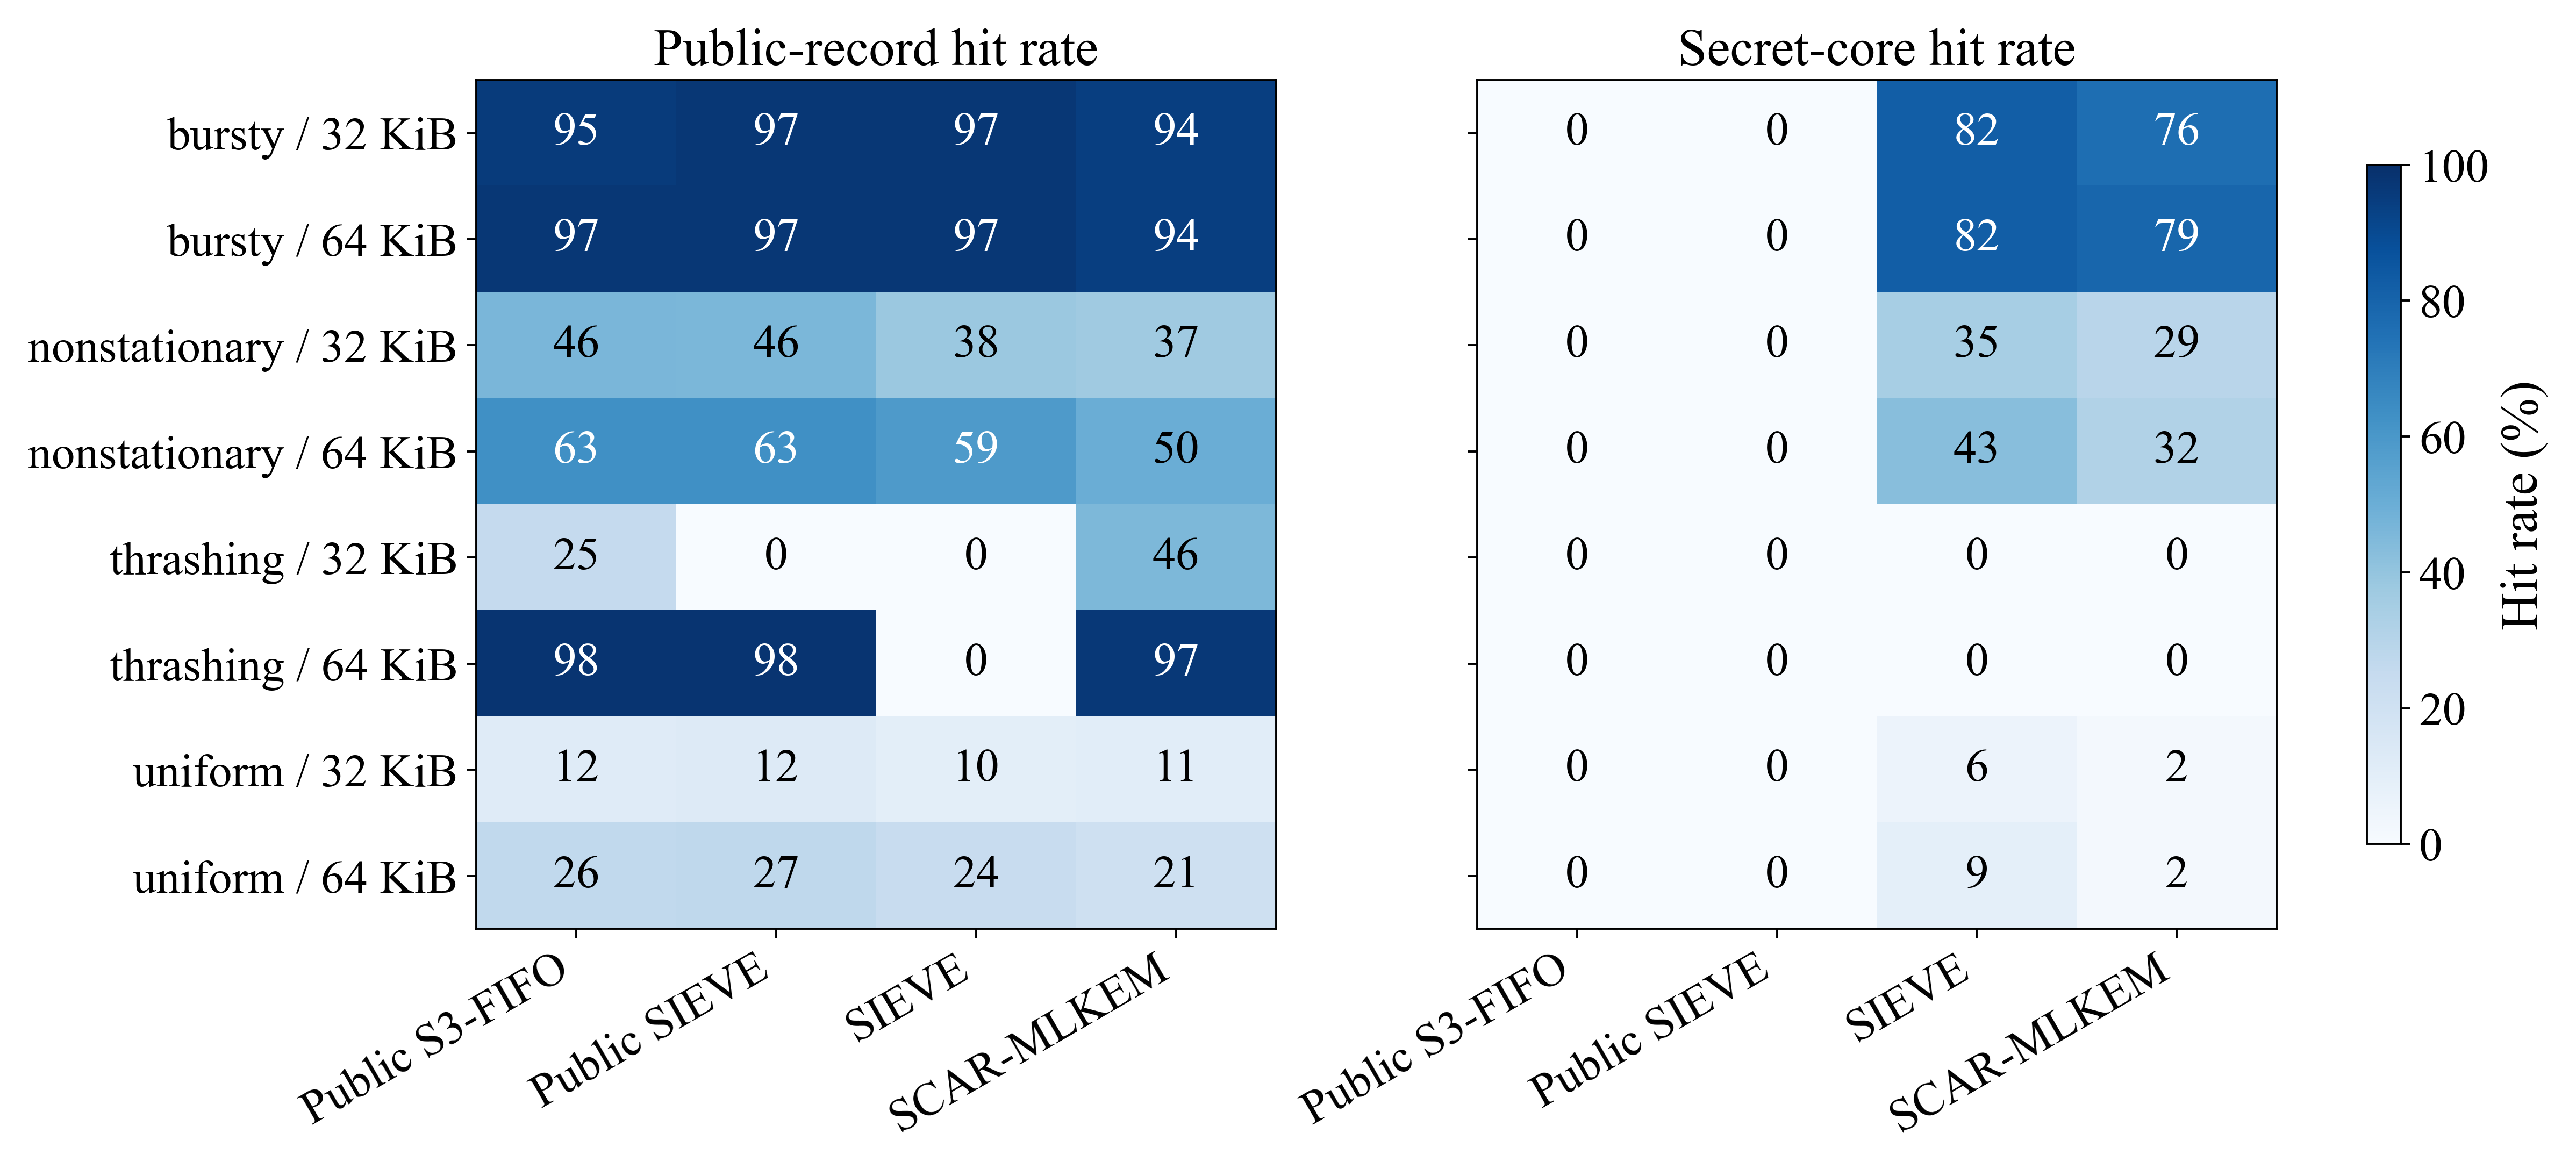

In [5]:
# Retention structure behind the CPU differences: public and secret hit rates (structure, not the same numbers as the table).
hits = s40.pivot_table(index="stratum", columns="setting", values=["public_hit", "secret_hit"], aggfunc="mean")
order = ["public_s3", "public_sieve", "sieve", "scar"]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.0), sharey=True)
for ax, kind, title in zip(axes, ["public_hit", "secret_hit"], ["Public-record hit rate", "Secret-core hit rate"]):
    matrix = hits[kind][order].values * 100
    im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(order))); ax.set_xticklabels([LABELS.get(o, "Public SIEVE") for o in order], rotation=30, ha="right")
    ax.set_yticks(range(len(hits.index))); ax.set_yticklabels(hits.index)
    ax.set_title(title)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix[i, j]:.0f}", ha="center", va="center", fontsize=18, color="white" if matrix[i, j] > 55 else "black")
fig.colorbar(im, ax=axes, shrink=0.8, label="Hit rate (%)")
check_font_sizes(fig)
save_figure(fig, "screen40_hit_structure", hits.reset_index())

**Interpretation.** On the eight strata already measured, the equal-stratum mean complete CPU is 38.19 µs for seed-only reconstruction, 34.70 µs for public S3-FIFO, 34.80 µs for public SIEVE, 38.30 µs for SIEVE and 34.03 µs for SCAR-MLKEM, that is 9.1 %, 8.9 %, −0.3 % and 10.9 % saving respectively. The heat maps show why: every retaining policy wins where contexts recur within the arena (bursty, thrashing at 64 KiB) and loses where recurrence is too sparse to repay admissions (uniform at both arenas, where all caches cost 1–6 % more than reconstruction). SCAR-MLKEM is the only policy that stays below reconstruction in thrashing at 32 KiB (5.8 % saving against −2.0 % for public S3-FIFO), because conditional admission refuses most unprofitable insertions (46 % public hits with far fewer admissions). Secret-core hits appear only in bursty and nonstationary traffic; in uniform and thrashing workloads the 10 ms lifetime expires before reuse. This screen covers four families and one seed per stratum, so it motivates, but cannot establish, the development conclusions of Sections 6–9.

## 4. Logical ceiling of secret retention under the lifetime and barrier limits

**Question.** Before measuring any new variant: with the public-record path fixed to what public S3-FIFO achieved, how much CPU could *any* secret-retention rule save at lifetimes $T\in\{10,20,50,100\}$ ms, with and without the mandatory 64-request monitor barrier? **Method.** Exact interval optimisation on the recorded public S3-FIFO request traces of the 40-process screen: each retained secret interval is a lease that must start after an access, end before $T-g$ and before the next barrier, and pays $a_S+e_S$; its benefit is $\max(0, C_{p,0}-C_{p,1})$ per later request of the same context. Zero-duration service, infinite secret capacity, clairvoyant future and zero controller work make this an optimistic bound, not a method.

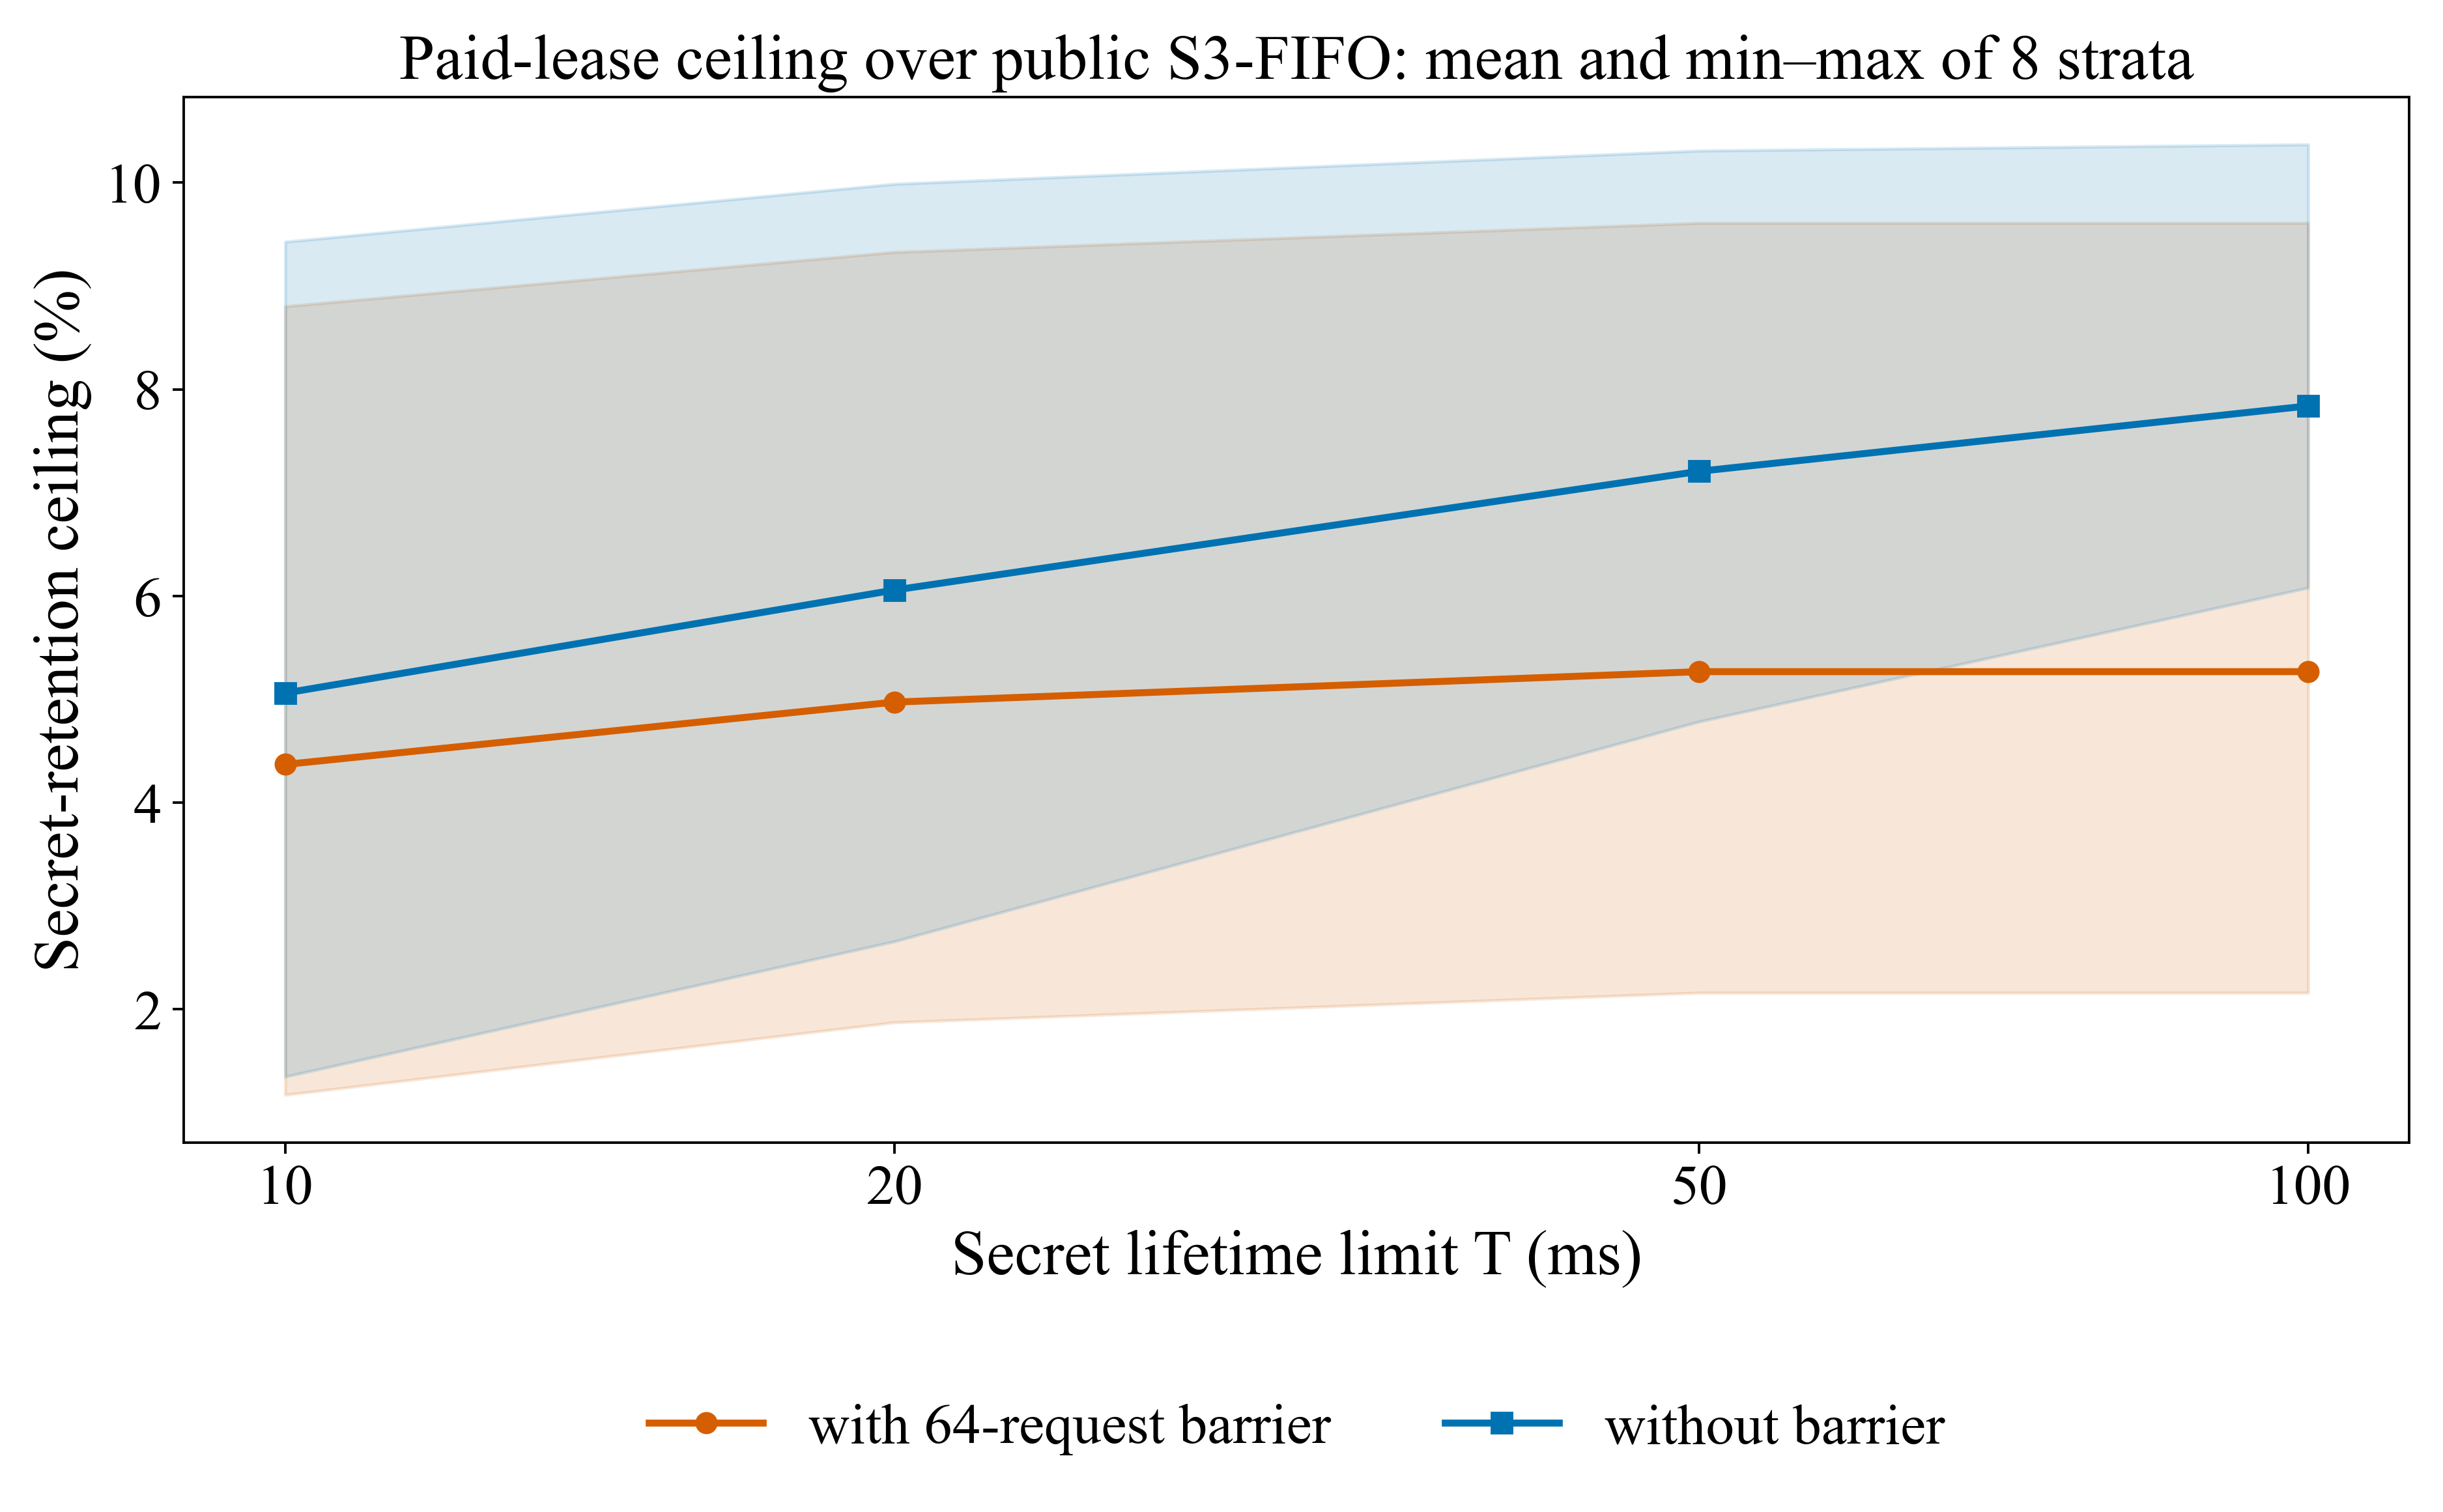

,barrier,T (ms),Mean ceiling (%),Min stratum (%),Max stratum (%)
0,with 64-request barrier,10,4.370,1.173,8.802
1,with 64-request barrier,20,4.973,1.874,9.327
2,with 64-request barrier,50,5.268,2.161,9.609
3,with 64-request barrier,100,5.268,2.161,9.609
4,without barrier,10,5.060,1.349,9.427
5,without barrier,20,6.057,2.657,9.987
6,without barrier,50,7.206,4.785,10.309
7,without barrier,100,7.839,6.080,10.368


In [18]:
def paid_lease_optimum(times, gains, span, lease_cost):
    # Suffix DP over requests of one context inside one barrier block: leases are intervals (i, j].
    n = len(times); suffix = [0.0] * (n + 1); prefix = [0.0]
    for g in gains:
        assert g >= 0; prefix.append(prefix[-1] + g)
    for i in range(n - 2, -1, -1):
        best = suffix[i + 1]
        for j in range(i + 1, n):
            if times[j] - times[i] >= span:
                break
            best = max(best, prefix[j + 1] - prefix[i + 1] - lease_cost + suffix[j])
        suffix[i] = best
    return suffix[0] if n else 0.0
assert paid_lease_optimum([0], [3], 10, 1) == 0 and paid_lease_optimum([0, 1, 2], [3, 3, 3], 10, 1) == 5
assert paid_lease_optimum([0, 10], [3, 3], 10, 1) == 0 and paid_lease_optimum([0, 6, 12], [3, 3, 3], 10, 1) == 4

ceiling_rows = []
lease_cost = COSTS["addS"] + COSTS["eraseS"]
for item in s40_spec["plan"]:
    if item["setting"] != "public_s3":
        continue
    stem = s40_raw / "physical" / item["session_id"]
    trace = pd.read_csv(str(stem) + ".stdout.csv")
    control_cpu = int(read_json(str(stem) + ".receipt.json")["metadata"]["request_phase_thread_cpu_ns"]) / len(trace)
    gains = np.where(trace.public_hit | trace.public_admitted, COSTS["C10"] - COSTS["C11"], COSTS["C00"] - COSTS["C01"]).clip(min=0)
    trace = trace.assign(gain=gains, block=np.arange(len(trace)) // 64)
    for ttl_ms in (10, 20, 50, 100):
        span = ttl_ms * 1_000_000 - 500_000
        for barrier in (True, False):
            keys = ["block", "key_id"] if barrier else ["key_id"]
            saved = sum(paid_lease_optimum(g.schedule_ns.astype(int).tolist(), g.gain.tolist(), span, lease_cost)
                        for _, g in trace.groupby(keys, sort=False)) / len(trace)
            ceiling_rows.append(dict(stratum=f"{item['family']} / {item['arena_bytes'] // 1024} KiB", ttl_ms=ttl_ms,
                                     barrier="with 64-request barrier" if barrier else "without barrier",
                                     saved_ns=saved, control_cpu_ns=control_cpu, ceiling_percent=100 * saved / control_cpu))
ceiling = pd.DataFrame(ceiling_rows)
assert ceiling.ceiling_percent.between(0, 100).all()
# Aggregate as the ratio of equal-stratum means, the convention used for every relative effect in this study.
ceiling_agg = ceiling.groupby(["barrier", "ttl_ms"]).apply(lambda g: pd.Series({
    "mean": 100 * g.saved_ns.mean() / g.control_cpu_ns.mean(), "min": g.ceiling_percent.min(), "max": g.ceiling_percent.max()}), include_groups=False).reset_index()
fig, ax = plt.subplots(figsize=(10.5, 6.4))
for barrier, style in (("with 64-request barrier", dict(color=COLORS["scar"], marker="o")), ("without barrier", dict(color=COLORS["public_s3"], marker="s"))):
    sub = ceiling_agg[ceiling_agg.barrier == barrier]
    ax.plot(sub.ttl_ms, sub["mean"], label=barrier, linewidth=2.2, **style)
    ax.fill_between(sub.ttl_ms, sub["min"], sub["max"], color=style["color"], alpha=0.15)
ax.set_xscale("log"); ax.set_xticks([10, 20, 50, 100]); ax.set_xticklabels(["10", "20", "50", "100"]); ax.minorticks_off()
ax.set_xlabel("Secret lifetime limit T (ms)"); ax.set_ylabel("Secret-retention ceiling (%)")
ax.set_title("Paid-lease ceiling over public S3-FIFO: mean and min–max of 8 strata")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
check_font_sizes(fig)
save_figure(fig, "secret_retention_ceiling", ceiling)
save_table(ceiling_agg.rename(columns={"ttl_ms": "T (ms)", "mean": "Mean ceiling (%)", "min": "Min stratum (%)", "max": "Max stratum (%)"}), "secret_retention_ceiling_summary")

**Interpretation.** With the public path of S3-FIFO fixed, no secret-retention rule can save more than 4.37 % of complete CPU at $T=10$ ms under the barrier, 4.97 % at 20 ms and 5.27 % at 50 ms, where the 64-request barrier (32 ms of schedule time) caps any longer lifetime. Removing the barrier would raise the ceiling to 7.84 % at 100 ms, but only by relaxing a safety control. The strata differ by an order of magnitude (1.2 % to 8.8 % at 10 ms). Two consequences follow. First, any increment of the adaptive controller over a strong public cache is bounded by this ceiling, so a few percent is the most that secret retention can add at the 10 ms lifetime. Second, the large savings reported below arise mostly from the shared public retention relative to seed-only reconstruction; the controller's own contribution is the smaller, bounded part, and the design decisions below treat it as such.

## 5. Prospective development series on Raspberry Pi 5

**Question.** Over all ten workload families, both arena budgets and three fresh development seeds per family, how do seed-only reconstruction, four strong fixed cache policies and SCAR-MLKEM compare in complete CPU, retention structure, tails, memory and lifecycle; which SCAR components matter; and how does the secret lifetime limit change the picture?

**Design (fixed before acquisition).** Replication unit: one native session (family, seed, arena). 10 families × 3 seeds × 2 arenas = 60 sessions. Settings: block A — `none` (seed-only standard), `public_s3`, `sieve`, `lecar`, `tiny`, `scar` at $T=10$ ms; block B — SCAR with each component removed (masks 30, 29, 27, 23, 15); block C — SCAR and SIEVE at $T=20$ and $50$ ms. 15 settings × 60 sessions = 900 processes of 1000 requests, run sequentially on CPU 2 under the `performance` governor with the frozen costs. Seeds are drawn from a range that no earlier experiment used. Public schedules are identical across settings of a session, so comparisons are paired. Processes that fail any native check are recorded and excluded from CPU means only after being counted.

In [7]:
DEV_ID = "development_20261020"
dev_seeds = {family: [4_100_000 + 10 * i + r for r in range(3)] for i, family in enumerate(FAMILIES)}
used = registered_seeds(exclude=MANIFESTS / "Development05" / DEV_ID)
assert not used.intersection(s for v in dev_seeds.values() for s in v), "development seeds must be fresh"
block_a = [dict(name=p, policy=p, components=31, ttl_ms=10) for p in POLICIES]
block_b = [dict(name=f"scar_minus_{c}", policy="scar", components=31 - bit, ttl_ms=10)
           for c, bit in (("age", 1), ("forget", 2), ("cost", 4), ("deadline", 8), ("admission", 16))]
block_c = [dict(name=f"{p}_ttl{t}", policy=p, components=31, ttl_ms=t) for p in ("scar", "sieve") for t in (20, 50)]
dev_plan = campaign_plan_rows(FAMILIES, dev_seeds, ARENAS, block_a + block_b + block_c, "development")
assert len(dev_plan) == 900
dev_reg, dev_spec = register_campaign("Development05", DEV_ID, dev_plan, split="development", native=NATIVE,
                                      extra=dict(costs_ns=COSTS, blocks=dict(A=[s["name"] for s in block_a], B=[s["name"] for s in block_b], C=[s["name"] for s in block_c])))
design = pd.DataFrame([dict(Block="A: policies at T = 10 ms", Settings=len(block_a), Sessions=60, Processes=60 * len(block_a)),
                       dict(Block="B: SCAR component removals", Settings=len(block_b), Sessions=60, Processes=60 * len(block_b)),
                       dict(Block="C: lifetime sensitivity (SCAR, SIEVE)", Settings=len(block_c), Sessions=60, Processes=60 * len(block_c))])
save_table(design, "development_design")

,Block,Settings,Sessions,Processes
0,A: policies at T = 10 ms,6,60,360
1,B: SCAR component removals,5,60,300
2,"C: lifetime sensitivity (SCAR, SIEVE)",4,60,240


In [8]:
dev_done = run_campaign(dev_reg, dev_spec)
dev = load_campaign(dev_spec, dev_done)
assert dev.status.eq("passed").sum() == dev_done["passed"] and len(dev) == 900
coverage = pd.DataFrame([dict(Processes=len(dev), Passed=int(dev.status.eq("passed").sum()), Failed=int(dev.status.ne("passed").sum()),
                              **{"Correct decapsulations": int(dev.status.eq("passed").sum() * dev_spec["requests"]),
                                 "Late secret clears": int(dev.late_clear_count.fillna(0).sum()),
                                 "Wall time (min)": dev.wall_seconds.sum() / 60,
                                 "Board temperature (°C) min": dev.temperature_c.min(), "Board temperature (°C) max": dev.temperature_c.max()})])
dev.to_csv(INTERIM / "05_development_sessions.csv", index=False)
save_table(coverage, "development_coverage")

,Processes,Passed,Failed,Correct decapsulations,Late secret clears,Wall time (min),Board temperature (°C) min,Board temperature (°C) max
0,900,900,0,900000,13,8.707,48.500,52.900


## 6. Complete CPU per request: policies against seed-only reconstruction

**Question.** How much of the standard reconstruction cost does each policy remove, in every stratum and on aggregate? **Method.** Paired within session; stratum means over three seeds; equal-stratum aggregate with a stratified bootstrap (10 000 resamples of sessions within strata) for 95 % intervals. Saving is $100\,(C_{\text{none}}-C_{\text{policy}})/C_{\text{none}}$.

In [9]:
A = dev[dev.setting.isin(POLICIES) & dev.status.eq("passed")].copy()
wide = A.pivot_table(index=["stratum", "family", "arena_bytes", "seed"], columns="setting", values="cpu_us").reset_index()
assert wide[POLICIES].notna().all().all(), "every session must have all six settings"
for p in POLICIES[1:]:
    wide[f"saving_{p}"] = 100 * (wide["none"] - wide[p]) / wide["none"]
    wide[f"delta_{p}"] = wide["none"] - wide[p]
stratum_cpu = wide.groupby("stratum")[POLICIES].mean()
stratum_cpu = stratum_cpu.loc[[f"{f} / {a // 1024} KiB" for f in FAMILIES for a in ARENAS]].rename_axis(columns=None)
save_table(stratum_cpu.rename(columns=LABELS).add_suffix(" (µs)").reset_index(), "development_cpu_by_stratum")
agg_rows = []
for p in POLICIES[1:]:
    point, lo, hi, lower = stratified_bootstrap(wide[f"delta_{p}"], wide["stratum"], wide["none"])
    dpoint, dlo, dhi, _ = stratified_bootstrap(wide[f"delta_{p}"], wide["stratum"])
    agg_rows.append({"Policy": LABELS[p], "Saving vs seed-only (%)": point, "95 % CI low (%)": lo, "95 % CI high (%)": hi,
                     "One-sided 95 % lower bound (%)": lower, "Absolute saving (µs)": dpoint, "Absolute 95 % CI low (µs)": dlo, "Absolute 95 % CI high (µs)": dhi,
                     "Strata with saving > 0": int((wide.groupby("stratum")[f"saving_{p}"].mean() > 0).sum())})
save_table(pd.DataFrame(agg_rows), "development_saving_vs_seed_only")

,stratum,Seed-only (standard) (µs),Public S3-FIFO (µs),SIEVE (µs),LeCaR (µs),TinyLFU (µs),SCAR-MLKEM (µs)
0,uniform / 32 KiB,38.315,40.626,42.776,43.247,41.622,39.247
1,uniform / 64 KiB,38.327,39.467,43.017,42.998,42.074,38.530
2,poisson / 32 KiB,37.801,40.093,42.205,42.904,41.631,38.812
3,poisson / 64 KiB,37.819,38.948,42.564,43.347,42.303,38.148
4,zipf / 32 KiB,38.304,34.527,35.140,36.473,34.594,33.452
5,zipf / 64 KiB,38.219,32.919,33.894,34.858,33.530,32.252
6,bursty / 32 KiB,36.875,28.470,26.927,27.274,32.498,27.782
7,bursty / 64 KiB,36.931,28.239,27.101,27.064,28.528,27.722
8,periodic / 32 KiB,38.350,31.491,31.354,40.776,31.161,30.706
9,periodic / 64 KiB,38.312,31.307,31.529,31.410,31.309,30.677


,Policy,Saving vs seed-only (%),95 % CI low (%),95 % CI high (%),One-sided 95 % lower bound (%),Absolute saving (µs),Absolute 95 % CI low (µs),Absolute 95 % CI high (µs),Strata with saving > 0
0,Public S3-FIFO,10.472,10.406,10.537,10.417,3.992,3.967,4.018,15
1,SIEVE,4.559,4.445,4.673,4.464,1.738,1.695,1.782,13
2,LeCaR,2.317,2.180,2.449,2.201,0.883,0.831,0.934,12
3,TinyLFU,6.042,5.906,6.167,5.927,2.303,2.251,2.351,12
4,SCAR-MLKEM,11.557,11.472,11.642,11.485,4.406,4.373,4.439,16


In [10]:
# SCAR against the strongest fixed policies, paired per session (the adaptive increment over fixed caches).
contrast_rows = []
for p in ["public_s3", "sieve", "lecar", "tiny"]:
    point, lo, hi, lower = stratified_bootstrap(wide[p] - wide["scar"], wide["stratum"], wide[p])
    per_stratum = (100 * (wide[p] - wide["scar"]) / wide[p]).groupby(wide["stratum"]).mean()
    contrast_rows.append({"Comparison": f"SCAR-MLKEM vs {LABELS[p]}", "CPU saving (%)": point, "95 % CI low (%)": lo, "95 % CI high (%)": hi,
                          "One-sided 95 % lower bound (%)": lower, "Strata where SCAR is lower": int((per_stratum > 0).sum()),
                          "Worst stratum (%)": per_stratum.min(), "Best stratum (%)": per_stratum.max()})
save_table(pd.DataFrame(contrast_rows), "development_scar_vs_fixed_policies")

,Comparison,CPU saving (%),95 % CI low (%),95 % CI high (%),One-sided 95 % lower bound (%),Strata where SCAR is lower,Worst stratum (%),Best stratum (%)
0,SCAR-MLKEM vs Public S3-FIFO,1.212,1.101,1.328,1.119,14,-3.419,8.089
1,SCAR-MLKEM vs SIEVE,7.332,7.192,7.469,7.213,18,-3.178,34.074
2,SCAR-MLKEM vs LeCaR,9.459,9.337,9.586,9.357,18,-2.432,28.342
3,SCAR-MLKEM vs TinyLFU,5.870,5.732,6.018,5.752,20,0.053,14.510


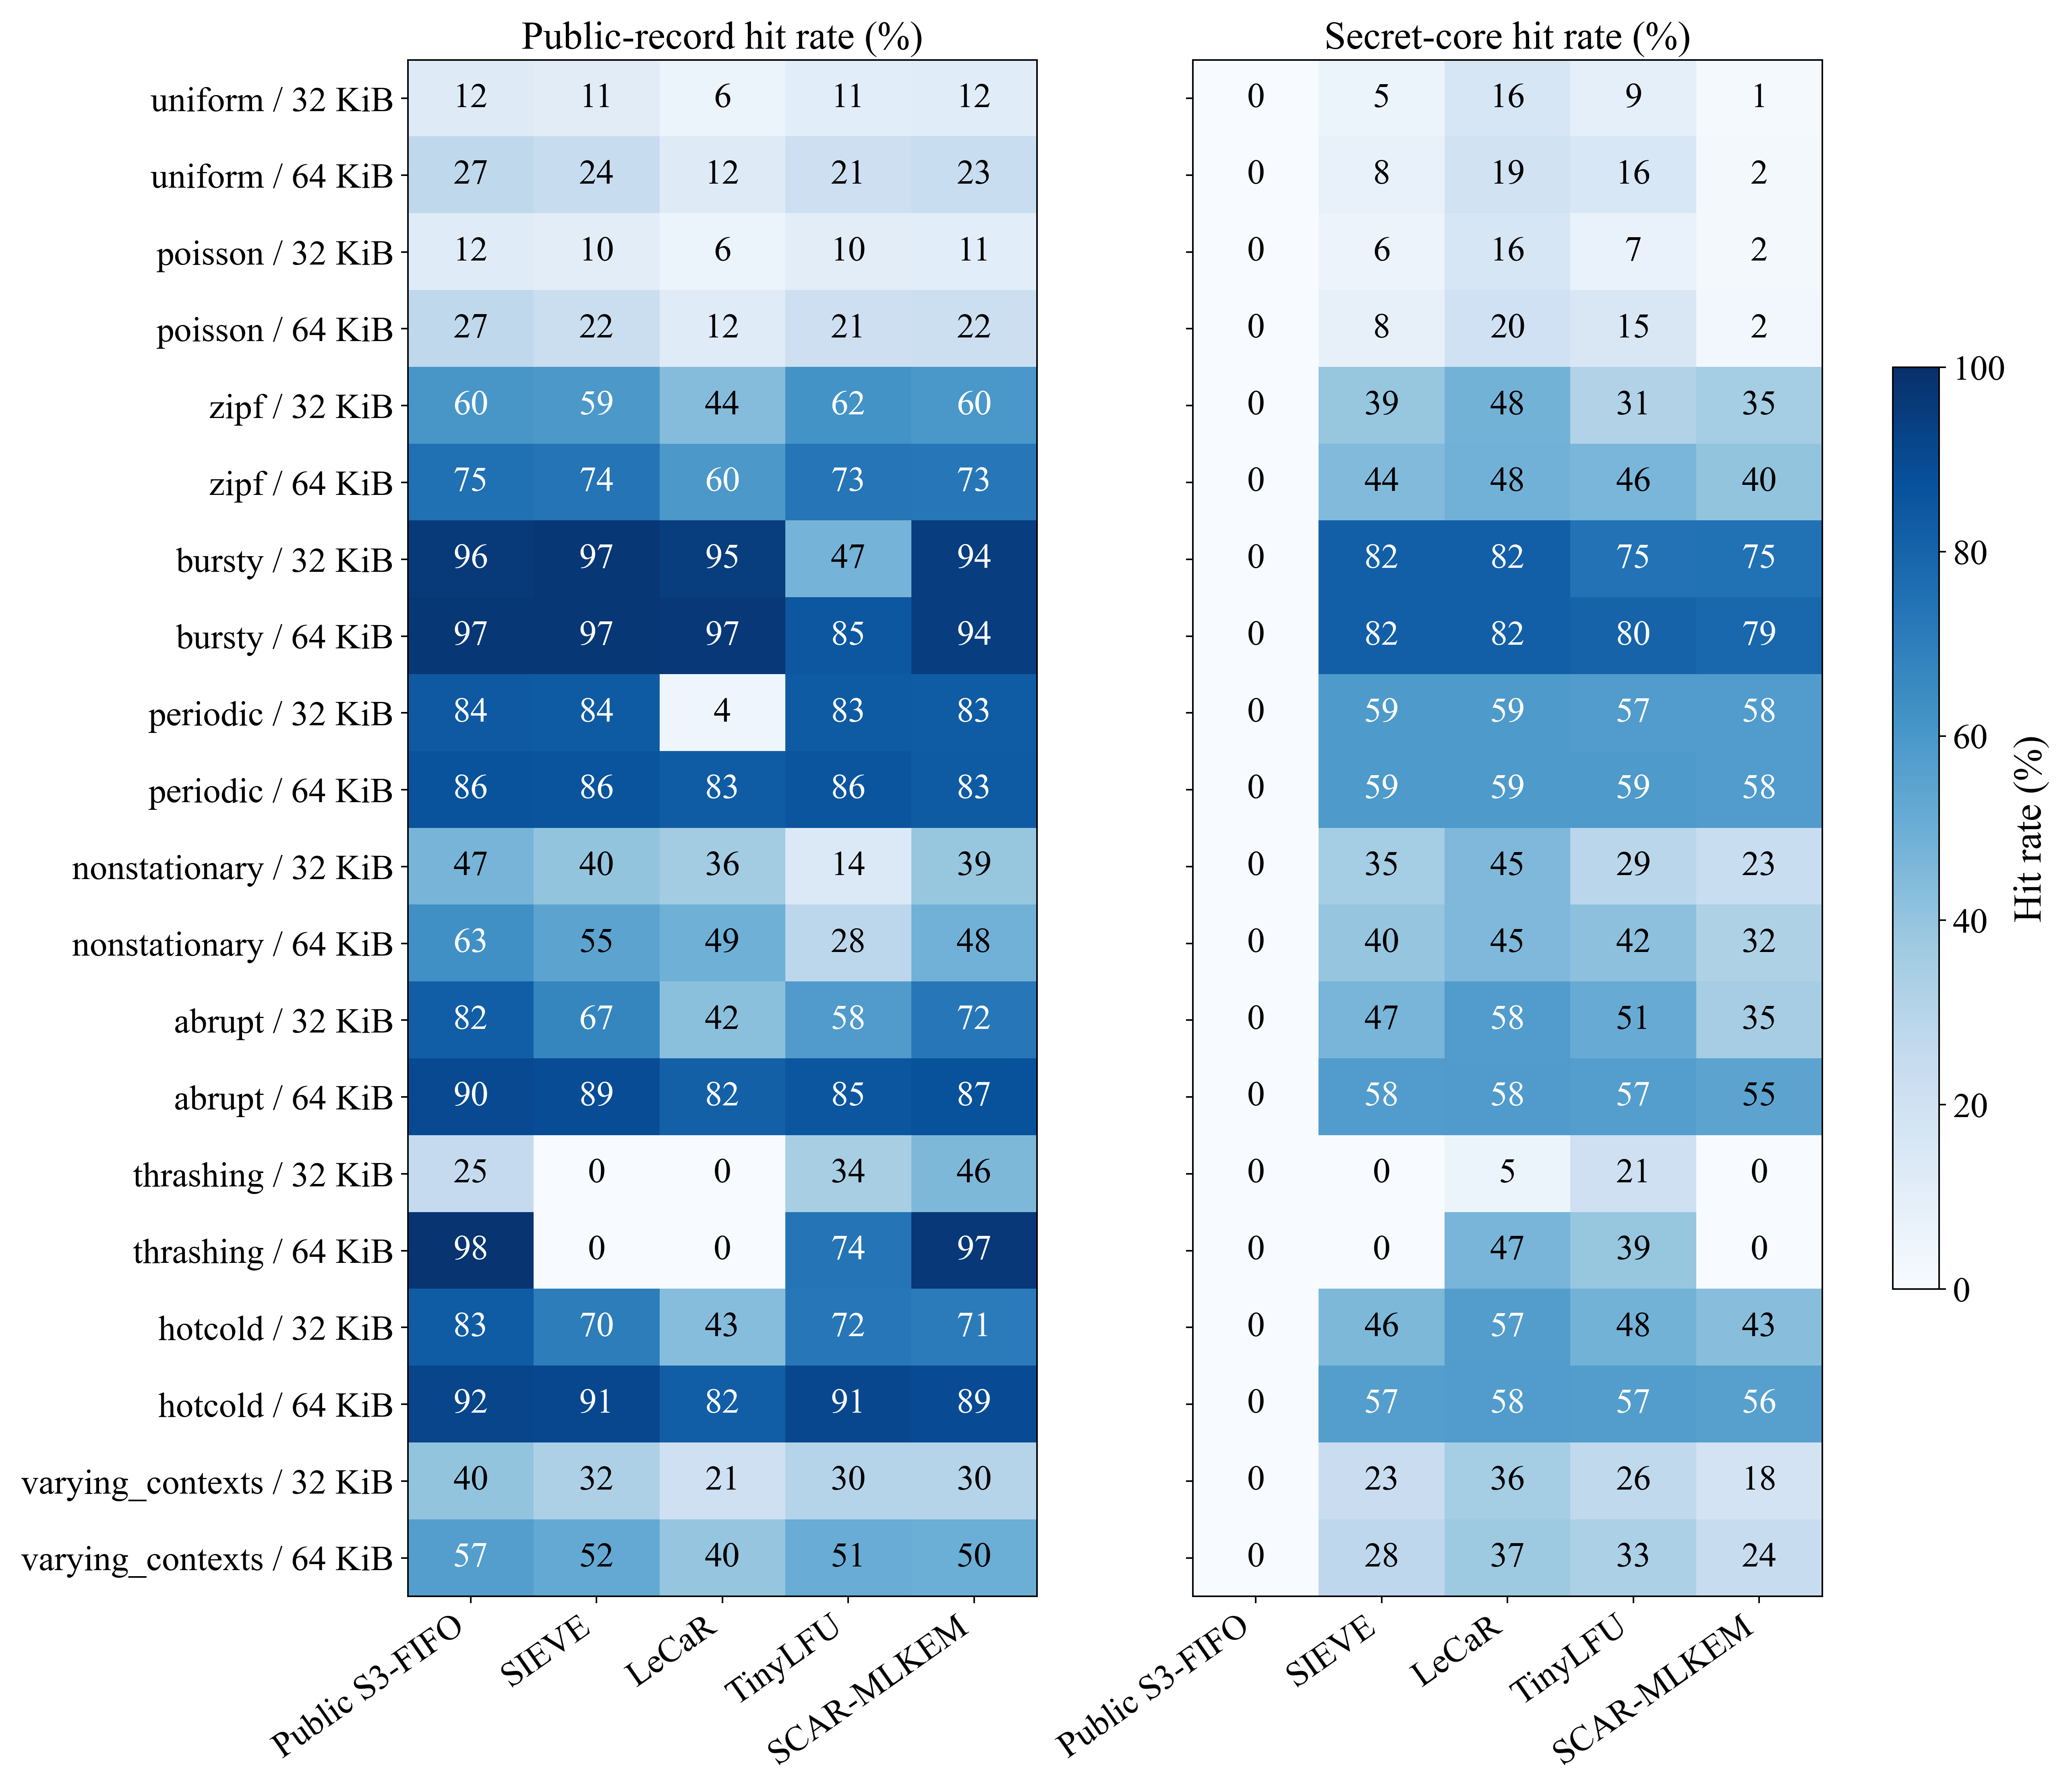

In [11]:
# Retention structure of the development series: hit rates by stratum and policy (heat maps, values annotated).
hit_wide = A.pivot_table(index="stratum", columns="setting", values=["public_hit", "secret_hit"], aggfunc="mean")
hit_wide = hit_wide.loc[stratum_cpu.index]
order = ["public_s3", "sieve", "lecar", "tiny", "scar"]
fig, axes = plt.subplots(1, 2, figsize=(14.5, 12.5), sharey=True)
for ax, kind, title in zip(axes, ["public_hit", "secret_hit"], ["Public-record hit rate (%)", "Secret-core hit rate (%)"]):
    matrix = hit_wide[kind][order].values * 100
    im = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(len(order))); ax.set_xticklabels([LABELS[o] for o in order], rotation=35, ha="right")
    ax.set_yticks(range(len(hit_wide.index))); ax.set_yticklabels(hit_wide.index); ax.set_title(title)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix[i, j]:.0f}", ha="center", va="center", fontsize=18, color="white" if matrix[i, j] > 55 else "black")
fig.colorbar(im, ax=axes, shrink=0.6, label="Hit rate (%)")
check_font_sizes(fig)
save_figure(fig, "development_hit_structure", hit_wide.reset_index())

In [12]:
# Where the CPU goes: stage decomposition per policy (instrumented wall regions, descriptive only).
stages = A.groupby("setting")[["reconstruction_ns", "decapsulation_ns", "public_prepare_ns", "planning_ns"]].mean().loc[POLICIES] / 1000
stages.columns = ["Reconstruction (µs)", "Decapsulation (µs)", "Public preparation (µs)", "Planning (µs)"]
stages.insert(0, "Complete CPU (µs)", A.groupby("setting").cpu_us.mean().loc[POLICIES])
stages.index = [LABELS[p] for p in POLICIES]
save_table(stages.rename_axis("Policy").reset_index(), "development_stage_decomposition")

,Policy,Complete CPU (µs),Reconstruction (µs),Decapsulation (µs),Public preparation (µs),Planning (µs)
0,Seed-only (standard),38.125,3.259,28.825,0.000,0.068
1,Public S3-FIFO,34.133,3.246,19.765,3.854,0.468
2,SIEVE,36.387,2.122,19.793,4.847,1.127
3,LeCaR,37.242,1.856,19.792,6.134,0.843
4,TinyLFU,35.822,2.034,23.852,0.378,1.928
5,SCAR-MLKEM,33.719,2.274,23.147,0.423,0.482


**Interpretation.** All 900 processes completed with correct shared secrets, on a board between 48.5 and 52.9 °C without throttling. Against seed-only reconstruction, SCAR-MLKEM saves 11.56 % of complete CPU (95 % interval 11.47–11.64 %, 4.41 µs per request), public S3-FIFO 10.47 %, TinyLFU 6.04 %, SIEVE 4.56 % and LeCaR 2.32 %. SCAR-MLKEM is below reconstruction in 16 of 20 strata; the four losses are the uniform and Poisson families (−0.5 % to −2.7 %), where every cache loses and the fixed caches lose more (−3 % to −6 % for public S3-FIFO). Against the strongest fixed policy, public S3-FIFO, the adaptive controller saves a further 1.21 % (1.10–1.33 %), lower in 14 of 20 strata, with its largest gain in thrashing at 32 KiB (8.1 %) and its largest loss in thrashing at 64 KiB (−3.4 %), where S3-FIFO retains the whole working set and SCAR's secret entries displace public records. The hit maps show the mechanism: SCAR-MLKEM matches the public hit rate of S3-FIFO within a few points in most strata and adds secret-core hits of 35–79 % wherever recurrence falls inside the 10 ms lifetime; TinyLFU and LeCaR under-retain public records in bursty, periodic and thrashing traffic. The stage decomposition confirms that controller work is small: mean planning time is 0.48 µs per request for SCAR against 0.47 µs for S3-FIFO and 1.9 µs for TinyLFU. Three seeds per stratum support the aggregate intervals, not per-stratum inference; those remain for Notebook 06.

## 7. Component ablations

**Question.** Does each SCAR component contribute on development data, or can it be removed without loss? **Method.** Block B removes one component at a time (same sessions, same schedules). The effect is the paired difference in complete CPU against the full method (mask 31), with a stratified bootstrap 95 % interval; positive values mean the component saves CPU.

In [13]:
B = dev[dev.status.eq("passed") & (dev.setting.eq("scar") | dev.setting.str.startswith("scar_minus"))]
abl_wide = B.pivot_table(index=["stratum", "seed", "arena_bytes"], columns="setting", values="cpu_us").reset_index()
hit_b = B.groupby("setting")[["public_hit", "secret_hit", "planning_ns"]].mean()
abl_rows = [{"Variant": "Full SCAR-MLKEM (mask 31)", "Complete CPU (µs)": abl_wide["scar"].mean(), "Effect of component (µs)": 0.0,
             "95 % CI low (µs)": 0.0, "95 % CI high (µs)": 0.0, "Public hit (%)": 100 * hit_b.loc["scar", "public_hit"],
             "Secret hit (%)": 100 * hit_b.loc["scar", "secret_hit"], "Planning (µs)": hit_b.loc["scar", "planning_ns"] / 1000}]
for name, label in (("scar_minus_age", "without AGE"), ("scar_minus_forget", "without FORGET"), ("scar_minus_cost", "without COST"),
                    ("scar_minus_deadline", "without DEADLINE"), ("scar_minus_admission", "without ADMISSION")):
    effect = abl_wide[name] - abl_wide["scar"]
    point, lo, hi, _ = stratified_bootstrap(effect, abl_wide["stratum"])
    abl_rows.append({"Variant": label, "Complete CPU (µs)": abl_wide[name].mean(), "Effect of component (µs)": point, "95 % CI low (µs)": lo,
                     "95 % CI high (µs)": hi, "Public hit (%)": 100 * hit_b.loc[name, "public_hit"], "Secret hit (%)": 100 * hit_b.loc[name, "secret_hit"],
                     "Planning (µs)": hit_b.loc[name, "planning_ns"] / 1000})
save_table(pd.DataFrame(abl_rows), "development_component_ablations")

,Variant,Complete CPU (µs),Effect of component (µs),95 % CI low (µs),95 % CI high (µs),Public hit (%),Secret hit (%),Planning (µs)
0,Full SCAR-MLKEM (mask 31),33.719,0.000,0.000,0.000,59.212,31.912,0.482
1,without AGE,35.499,1.780,1.681,1.877,46.412,7.235,0.800
2,without FORGET,33.756,0.037,0.011,0.062,62.377,0.000,0.278
3,without COST,35.918,2.199,2.113,2.287,56.823,29.053,0.967
4,without DEADLINE,34.561,0.842,0.808,0.877,56.585,36.743,1.086
5,without ADMISSION,33.883,0.164,0.128,0.202,59.227,31.868,0.609


**Interpretation.** Every component has a positive paired effect with a bootstrap interval excluding zero, so none is removed: COST saves 2.20 µs per request (2.11–2.29), AGE 1.78 µs (1.68–1.88), DEADLINE 0.84 µs (0.81–0.88), ADMISSION 0.16 µs (0.13–0.20) and FORGET 0.04 µs (0.01–0.06). Removing COST or AGE roughly doubles planning time and lowers hit rates, because value estimates without measured costs or decay admit entries that are never repaid. Removing FORGET disables secret-core retention entirely (0 % secret hits) yet changes CPU by only 0.04 µs: the public tier delivers nearly all of the saving, and the secret tier's net contribution on these workloads is of the order of the ceiling analysis in Section 4. The full composition (mask 31) is therefore retained, with the explicit caveat that the secret-core mechanism is a small, bounded increment rather than the main source of the gain.

## 8. Sensitivity to the secret lifetime limit

**Question.** Is the SCAR result specific to $T=10$ ms? **Method.** Block C repeats SCAR and SIEVE at $T=20$ and $50$ ms on the same sessions; the 64-request monitor barrier still clears secrets every 32 ms of schedule time, so $T=50$ ms is effectively barrier-limited. The figure shows the aggregate CPU saving against seed-only with bootstrap intervals; the table lists the lifecycle quantities that the figure does not show.

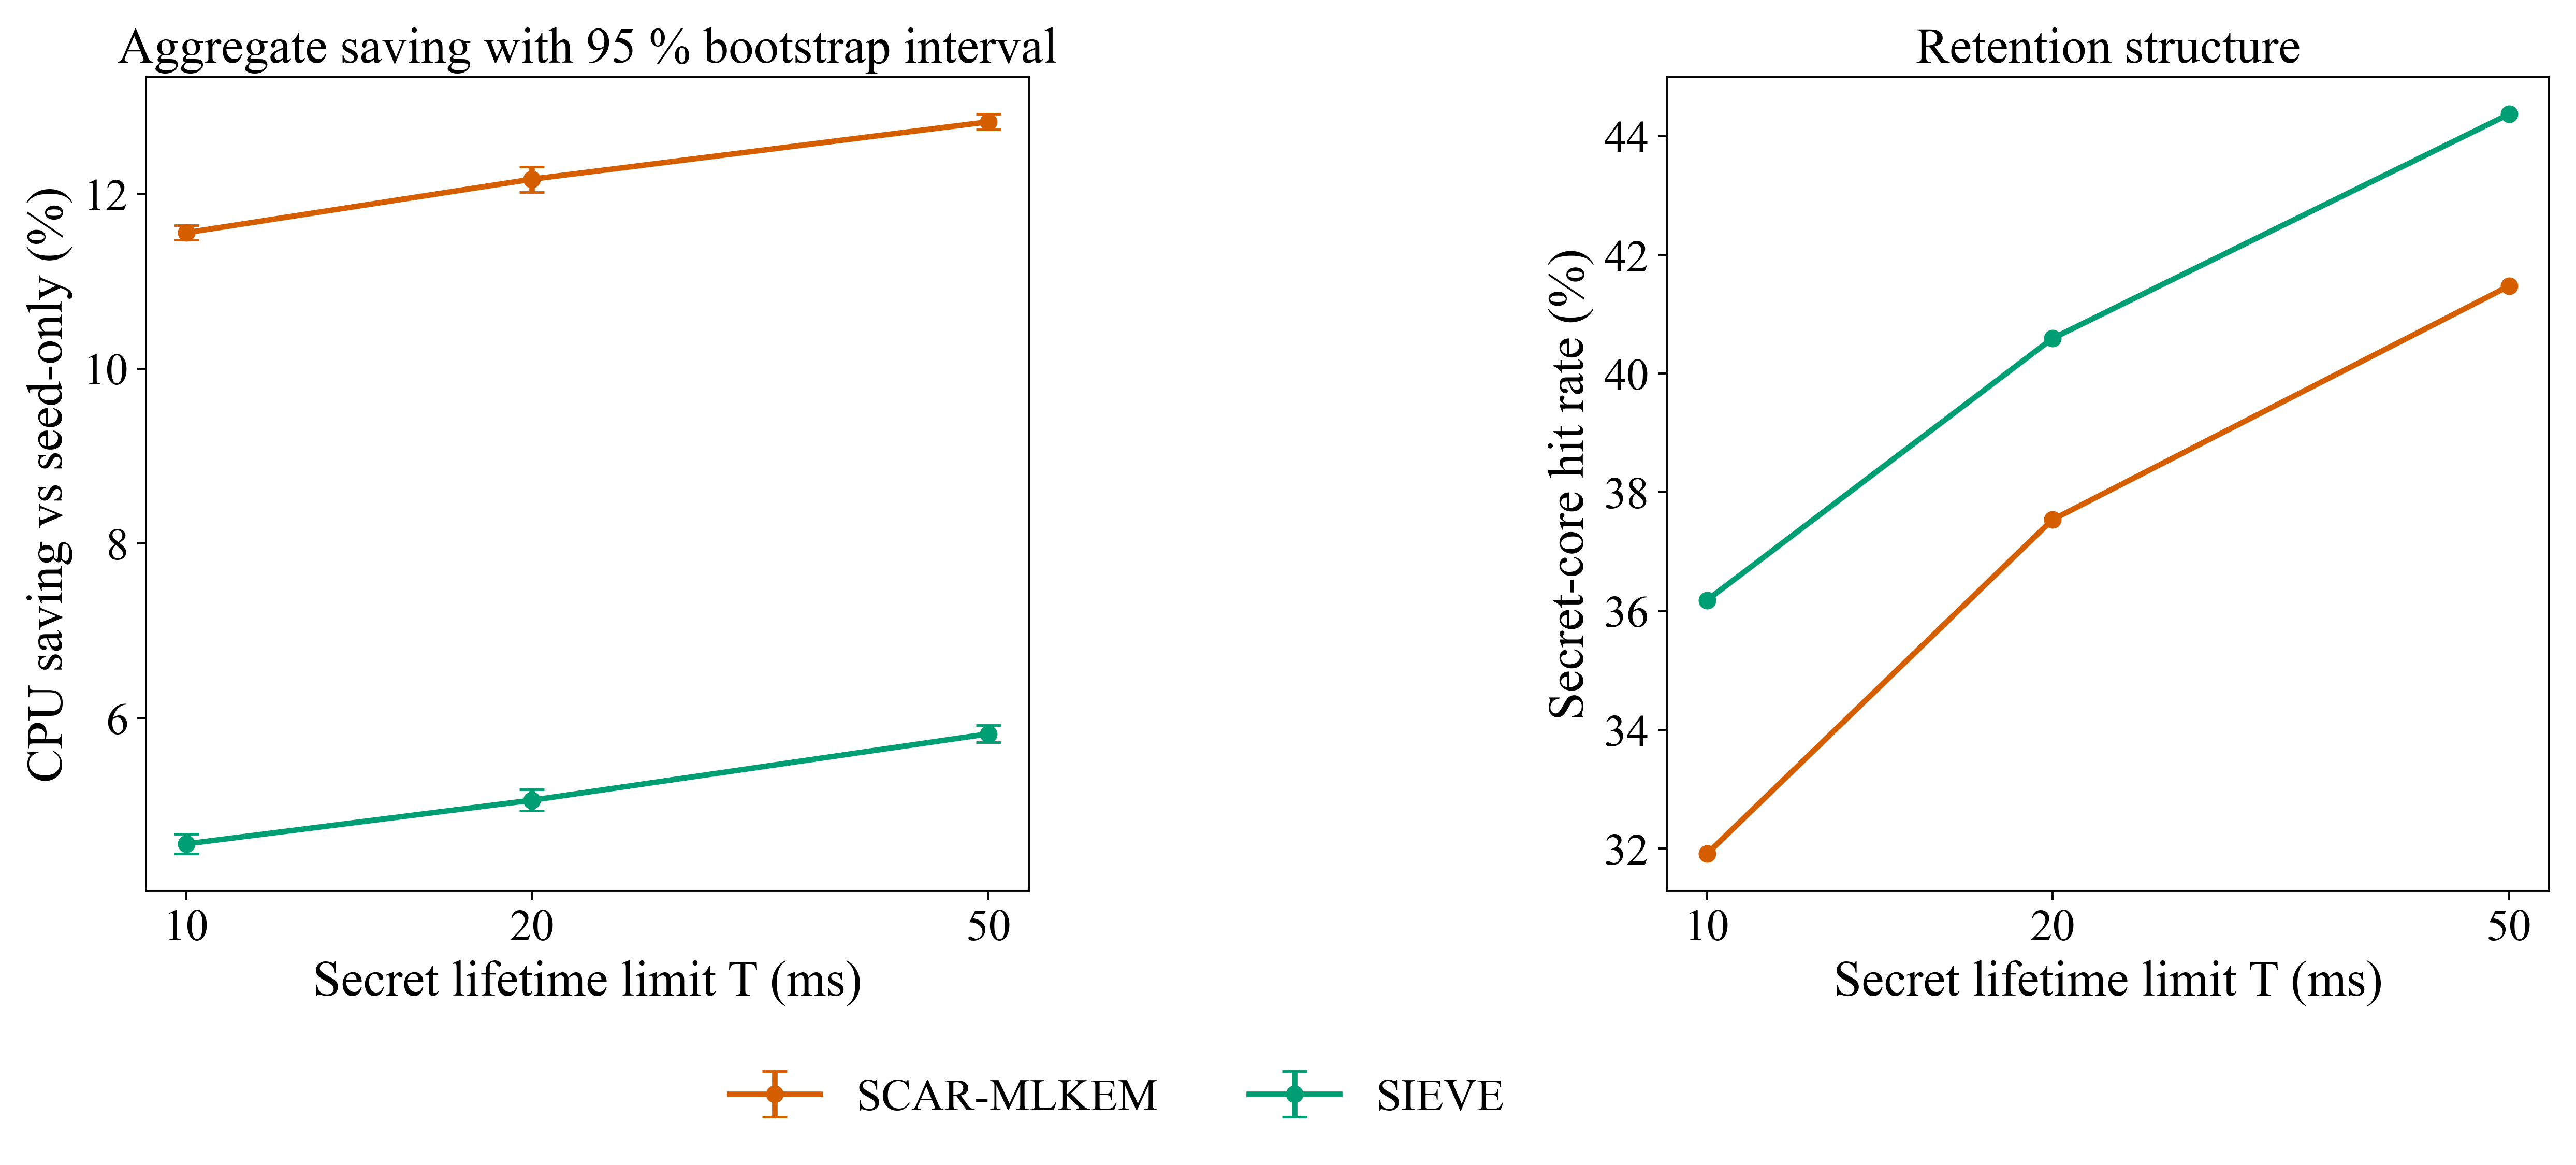

,Policy,T (ms),Max secret residency (ms),Late clears,Sessions
0,SCAR-MLKEM,10,9.572,0,60
1,SCAR-MLKEM,20,20.948,2,60
2,SCAR-MLKEM,50,38.783,0,60
3,SIEVE,10,10.115,1,60
4,SIEVE,20,19.891,0,60
5,SIEVE,50,38.784,0,60


In [14]:
C = dev[dev.status.eq("passed") & dev.policy.isin(["scar", "sieve"]) & dev.components.eq(31)].copy()
base = dev[dev.status.eq("passed") & dev.setting.eq("none")].set_index(["stratum", "seed", "arena_bytes"]).cpu_us
C["none_cpu"] = C.set_index(["stratum", "seed", "arena_bytes"]).index.map(base)
sens_rows = []
for (policy, ttl), g in C.groupby(["policy", "ttl_ms"]):
    point, lo, hi, _ = stratified_bootstrap(g.none_cpu - g.cpu_us, g.stratum, g.none_cpu)
    sens_rows.append(dict(policy=policy, ttl_ms=ttl, saving=point, lo=lo, hi=hi, secret_hit=100 * g.secret_hit.mean(),
                          residency_ms=g.secret_max_residency_ms.max(), late_clears=int(g.late_clear_count.sum()), sessions=len(g)))
sens = pd.DataFrame(sens_rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for policy in ("scar", "sieve"):
    sub = sens[sens.policy == policy]
    axes[0].errorbar(sub.ttl_ms, sub.saving, yerr=[sub.saving - sub.lo, sub.hi - sub.saving], marker="o", capsize=5, linewidth=2.2, color=COLORS[policy], label=LABELS[policy])
    axes[1].plot(sub.ttl_ms, sub.secret_hit, marker="o", linewidth=2.2, color=COLORS[policy], label=LABELS[policy])
for ax, ylabel in zip(axes, ["CPU saving vs seed-only (%)", "Secret-core hit rate (%)"]):
    ax.set_xscale("log"); ax.set_xticks([10, 20, 50]); ax.set_xticklabels(["10", "20", "50"]); ax.minorticks_off()
    ax.set_xlabel("Secret lifetime limit T (ms)"); ax.set_ylabel(ylabel)
axes[0].set_title("Aggregate saving with 95 % bootstrap interval"); axes[1].set_title("Retention structure")
axes[0].legend(loc="upper center", bbox_to_anchor=(1.1, -0.18), ncol=2)
check_font_sizes(fig)
save_figure(fig, "lifetime_sensitivity", sens)
save_table(sens[["policy", "ttl_ms", "residency_ms", "late_clears", "sessions"]].assign(policy=lambda d: d.policy.map(LABELS))
           .rename(columns={"policy": "Policy", "ttl_ms": "T (ms)", "residency_ms": "Max secret residency (ms)", "late_clears": "Late clears", "sessions": "Sessions"}),
           "lifetime_sensitivity_lifecycle")

**Interpretation.** Raising the secret lifetime from 10 to 20 and 50 ms increases SCAR-MLKEM's saving from 11.56 % to 12.17 % and 12.83 %, and its secret-core hit rate from 32 % to 38 % and 41 %; SIEVE gains similarly (4.56 % to 5.82 %). The gain flattens above 20 ms because the 64-request barrier clears secrets after at most 32 ms of schedule time (observed maximum residency 38.8 ms at $T=50$ ms, 20.9 ms at 20 ms). The result at 10 ms is therefore conservative but not fragile. The lifetime stays frozen at 10 ms: a longer limit keeps expanded secret material resident longer and would change the security posture rather than the algorithm, so it is reported as sensitivity only. One late clear of SIEVE and two of SCAR at 20 ms show that Linux scheduling can overshoot any guard; the rates are counted, not hidden.

## 9. Tails, memory and lifecycle on development data

**Question.** Does retention buy CPU at the expense of response tails, memory or secret-lifetime discipline? **Method.** Per-session p95/p99 response (scheduled arrival to completion), peak RSS, retained mapping and the recorded secret-lifetime endpoints, aggregated over the 60 sessions of block A.

In [15]:
tails = []
for p in POLICIES:
    g = A[A.setting == p]; ref = A[A.setting == "none"].set_index(["stratum", "seed", "arena_bytes"])
    gi = g.set_index(["stratum", "seed", "arena_bytes"])
    tails.append({"Policy": LABELS[p], "Response p95 (µs)": g.response_p95_us.mean(), "Response p99 (µs)": g.response_p99_us.mean(),
                  "p95 ratio vs seed-only (median)": (gi.response_p95_us / ref.response_p95_us).median(),
                  "p99 ratio vs seed-only (median)": (gi.response_p99_us / ref.response_p99_us).median(),
                  "Peak RSS (MiB)": g.peak_rss_bytes.mean() / 2**20, "Retained mapping (KiB)": g.retained_mapping_bytes.mean() / 1024,
                  "Peak arena occupancy (KiB)": g.peak_occupied_bytes.mean() / 1024, "Policy metadata (bytes)": g.policy_bytes.mean(),
                  "Late clears": int(g.late_clear_count.sum()), "Max lateness (µs)": g.max_lateness_us.max(),
                  "Max secret residency (ms)": g.secret_max_residency_ms.max()})
save_table(pd.DataFrame(tails), "development_tails_memory_lifecycle")

,Policy,Response p95 (µs),Response p99 (µs),p95 ratio vs seed-only (median),p99 ratio vs seed-only (median),Peak RSS (MiB),Retained mapping (KiB),Peak arena occupancy (KiB),Policy metadata (bytes),Late clears,Max lateness (µs),Max secret residency (ms)
0,Seed-only (standard),89.533,92.396,1.000,1.000,23.086,128.000,1.531,0.000,0,0.000,0.000
1,Public S3-FIFO,91.814,96.917,1.046,1.052,23.111,128.000,45.891,624.000,0,0.000,0.000
2,SIEVE,95.067,99.699,1.070,1.072,23.128,128.000,47.814,32.000,1,114.555,10.115
3,LeCaR,94.247,98.572,1.066,1.066,23.128,128.000,40.485,2496.000,0,0.000,9.894
4,TinyLFU,95.471,112.905,1.061,1.075,23.153,128.000,47.727,1184.000,9,2478.537,12.479
5,SCAR-MLKEM,90.913,96.764,1.022,1.054,23.153,128.000,44.871,1824.000,0,0.000,9.572


**Interpretation.** Retention costs a few percent of response tail: SCAR-MLKEM's median per-session p95 ratio against seed-only is 1.022 and its p99 ratio 1.054, the lowest p95 and a p99 comparable to public S3-FIFO (1.046 and 1.052); SIEVE, LeCaR and TinyLFU sit at 1.06–1.08, and TinyLFU's mean p99 reaches 112.9 µs. Memory is flat: peak RSS is 23.09–23.15 MiB for every policy, the retained locked mapping is 128 KiB by construction, and policy metadata ranges from 32 bytes (SIEVE) to 2.5 KiB (LeCaR), 1.8 KiB for SCAR-MLKEM. Lifecycle discipline differs: in block A, SCAR-MLKEM recorded no late clear in 60 sessions (maximum residency 9.57 ms against the 10 ms limit), SIEVE one late clear of 115 µs, and TinyLFU nine late clears with a maximum lateness of 2.48 ms. The guard does not make Linux a hard real-time system; the frozen protocol therefore reports lateness as an endpoint rather than a gate.

## 10. Frozen design and plan of the independent confirmation

**Decision rule (fixed in advance).** The architecture frozen for Notebook 06 is the full SCAR-MLKEM (mask 31) at $T=10$ ms unless block B shows a component whose removal lowers CPU with a bootstrap interval excluding zero; the lifetime limit stays at 10 ms regardless of block C, because a longer limit changes the security posture and is reported only as sensitivity. The confirmation compares the frozen method with seed-only reconstruction (primary) and with the four fixed policies (secondary) on six reserved seeds per family that have never been generated, with the inference rules written below before any test process runs.

In [16]:
abl = pd.DataFrame(abl_rows).set_index("Variant")
removable = abl[(abl["Effect of component (µs)"] < 0) & (abl["95 % CI high (µs)"] < 0)]
final_mask = 31
for label, bit in (("without AGE", 1), ("without FORGET", 2), ("without COST", 4), ("without DEADLINE", 8), ("without ADMISSION", 16)):
    if label in removable.index:
        final_mask -= bit
FREEZE = dict(schema="scar_mlkem_final_freeze_v2", frozen_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
              method="SCAR-MLKEM", policy="scar", components=final_mask, scar=dict(k=0, nu=2, margin=0), ttl_ms=10, guard_us=500,
              horizon_ms=10, history_capacity=1000, contexts=64, requests=1000, interval_us=500, arenas=ARENAS, native=NATIVE,
              costs_ns=COSTS, costs_source=acquisition_path(cost_path), development_campaign=acquisition_path(dev_reg),
              competitors=dict(primary="none", secondary=["public_s3", "sieve", "lecar", "tiny"]),
              primary_endpoint="paired complete request-phase thread CPU per request, session level, equal-stratum mean over 20 strata",
              inference=dict(resamples=10000, interval="stratified percentile bootstrap over sessions within strata", alpha=0.05,
                             secondary_adjustment="Holm over four one-sided paired comparisons", tails="p95/p99 response ratio with bootstrap interval",
                             lifecycle="late secret clears counted and reported; no process is excluded for lateness",
                             exclusion="a process without native success is excluded from CPU means and reported"),
              test_seed_namespace=7_000_000, seeds_per_family=6)
freeze_path = CONFIGS / "scar_mlkem_final_freeze_20261020.json"
if freeze_path.exists():
    FREEZE["frozen_utc"] = read_json(freeze_path)["frozen_utc"]
write_json(freeze_path, FREEZE)
test_seeds = {family: [7_000_000 + 10 * i + r for r in range(6)] for i, family in enumerate(FAMILIES)}
assert not registered_seeds(exclude=MANIFESTS / "Confirmation06/confirmation_20261020").intersection(s for v in test_seeds.values() for s in v), "reserved test seeds must never have been registered"
conf_settings = [dict(name=p, policy=p, components=final_mask if p == "scar" else 31, ttl_ms=10) for p in POLICIES]
conf_plan = campaign_plan_rows(FAMILIES, test_seeds, ARENAS, conf_settings, "test")
conf_reg, conf_spec = register_campaign("Confirmation06", "confirmation_20261020", conf_plan, split="test", native=NATIVE,
                                        extra=dict(costs_ns=COSTS, freeze_sha256=sha(freeze_path), freeze=acquisition_path(freeze_path)))
frozen_table = pd.DataFrame([{"Parameter": k, "Value": v} for k, v in [("Method", "SCAR-MLKEM"), ("Component mask", final_mask),
    ("Forecast (k, ν, margin)", "0, 2, 0"), ("Secret lifetime T", "10 ms"), ("Guard", "500 µs"), ("Horizon", "10 ms"),
    ("History capacity", 1000), ("Arenas", "32 KiB, 64 KiB"), ("Contexts / requests per session", "64 / 1000"),
    ("Primary comparison", LABELS["none"]), ("Secondary comparisons", ", ".join(LABELS[p] for p in ["public_s3", "sieve", "lecar", "tiny"])),
    ("Confirmation processes", len(conf_plan)), ("Reserved seeds per family", 6)]])
save_table(frozen_table, "frozen_design")

,Parameter,Value
0,Method,SCAR-MLKEM
1,Component mask,31
2,"Forecast (k, ν, margin)","0, 2, 0"
3,Secret lifetime T,10 ms
4,Guard,500 µs
5,Horizon,10 ms
6,History capacity,1000
7,Arenas,"32 KiB, 64 KiB"
8,Contexts / requests per session,64 / 1000
9,Primary comparison,Seed-only (standard)


**Interpretation.** No component met the removal rule, so the frozen method is the full SCAR-MLKEM composition (mask 31) with the fixed forecast settings, the 10 ms lifetime and the frozen costs. The confirmation planned here uses 60 reserved seeds from a namespace that no manifest has ever used, 720 processes, and the inference rules written into the freeze file before any test process runs. Development numbers selected the design; they do not enter the confirmation.

## 11. Conclusions

**What development established.** On ten workload families, two arena budgets and three fresh seeds each, SCAR-MLKEM lowers the complete request-phase CPU of ML-KEM-768 decapsulation by 11.56 % (95 % bootstrap interval 11.47–11.64 %) relative to standard seed-only reconstruction, with every cryptographic check passing, no late secret clear at the 10 ms limit, flat memory and a p95 response ratio of 1.02. Most of this saving is shared with any strong public-record cache: public S3-FIFO reaches 10.47 %, and the adaptive controller adds 1.21 % (1.10–1.33 %) over it. The five components each contribute, with measured-cost charging and forecast ageing the largest. The logical ceiling of secret retention (4.37 % over S3-FIFO at 10 ms, barrier-capped at 5.27 %) explains why the controller's increment over a strong public cache is small.

**What remains open.** Four strata (uniform and Poisson) lose 0.5–2.7 % because recurrence is too sparse for any cache; a fallback to pure reconstruction in such regimes is a candidate for future work, not part of the frozen method. Three seeds per stratum support aggregate intervals only. Energy is unmeasured. Lateness beyond the guard occurs under Linux scheduling for secret-retaining policies and is reported as an endpoint.

**Next stage.** The frozen design, the six-policy competitor set, the primary and secondary endpoints and the inference rules are saved with the project configuration together with the confirmation plan on reserved seeds. Notebook 06 acquires that plan once and performs the prespecified inference.